In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05    # 95% 신뢰구간
MAXQ = 500      # 루프 내 최대 쿼리 수

# ===현재 노트북 환경에 맞게 수정===
DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"), "column": "Credit_Limit"},
    "Bank": {"path": Path("data/bank_exp.parquet"), "column": "credit_limit"},
}

# ===드라이브 전용===
# DATASETS = {
#     "CardBase": {"path": Path("/content/CardBase.csv"), "column": "Credit_Limit"},
#     "Bank": {"path": Path("/content/bank_exp.parquet"), "column": "credit_limit"},
# }

OUTPUT_DIR = Path("/content/outputs/result_single")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

> 시각화 정의
* `plt.rcParams.update`

In [37]:
# @title
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
})

> 데이터셋 로드
* `load_dataset()`

In [38]:
# @title
def load_dataset(path, column):
    path = Path(path)
    if path.suffix.lower() == ".csv":
        df = pd.read_csv(path)
    elif path.suffix.lower() == ".parquet":
        df = pd.read_parquet(path)
    else:
        raise ValueError(f"지원하지 않는 파일 형식: {path}")
    if column not in df.columns:
        raise KeyError(f"{path}에 {column!r} 열이 없습니다.")
    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0:
        raise ValueError(f"{path}의 {column!r} 열에 유효한 숫자가 없습니다.")
    n = len(x)
    return {
        "x": x,
        "n": n,
        "true_mean": float(x.mean()),
        "min": float(x.min()),
        "max": float(x.max()),
        "delta": float((x.max() - x.min()) / n),
    }

### 원본 데이터셋 통계 정보

In [39]:
DATA = {name: load_dataset(cfg["path"], cfg["column"])
        for name, cfg in DATASETS.items()}

# ===통계 정보를 DataFrame으로 변환===
pd.DataFrame([
    {"dataset": name, **{k: v for k, v in d.items() if k != "x"}}
    for name, d in DATA.items()
])

,dataset,n,true_mean,min,max,delta
0,CardBase,500,252614.000000,2000.0,899000.0,1794.000000
1,Bank,6744,9074.479537,1439.0,34516.0,4.904656


In [40]:
TRUE_MEAN = 252614.0

> 유틸리티 함수 정의
* `_statistics`: 현재까지의 응답값으로 누적 통계와 95% CI를 계산
* `_final_from_history`: ...
* `_validate_inputs`: 인풋값 유효성 검증

In [41]:
# @title
def _statistics(values, true_mean, alpha=ALPHA):
    """현재까지의 응답값으로 누적 통계와 95% CI를 계산한다."""
    values = np.asarray(values, dtype=float)


    # 응답 값 개수로 k를 계산함
    k = len(values)
    cumulative_mean = float(values.mean())

    if k < 2:
        return {
            "k": k, "response": float(values[-1]),
            "cumulative_mean": cumulative_mean,
            "sample_std": np.nan, "standard_error": np.nan,
            "moe": np.nan, "ci_lo": np.nan, "ci_hi": np.nan,
            "ci_width": np.nan, "relative_width": np.nan,
            "hit": False, "covered": pd.NA,
        }

    sample_std = float(values.std(ddof=1))
    standard_error = sample_std / np.sqrt(k)
    t_value = stats.t.ppf(1 - alpha / 2, df=k - 1)
    moe = float(t_value * standard_error)
    ci_lo = cumulative_mean - moe
    ci_hi = cumulative_mean + moe
    ci_width = float(2 * moe)
    relative_width = float(ci_width / abs(cumulative_mean)) if cumulative_mean != 0 else np.inf
    covered = bool(ci_lo <= true_mean <= ci_hi)

    return {
        "k": k, "response": float(values[-1]),
        "cumulative_mean": cumulative_mean,
        "sample_std": sample_std, "standard_error": standard_error,
        "moe": moe, "ci_lo": ci_lo, "ci_hi": ci_hi,
        "ci_width": ci_width, "relative_width": relative_width,
        "hit": False, "covered": covered,
    }

def _final_from_history(history, **metadata):
    # 히스토리 데이터에서 마지막 행을 꺼내서, 메타데이터를 덧붙여 반환
    row = history.iloc[-1].to_dict()
    row.update(metadata)
    return row

def _validate_inputs(eps, threshold, streak_required, maxq):
    if eps <= 0:
        raise ValueError("eps는 0보다 커야 합니다.")
    if threshold <= 0:
        raise ValueError("threshold는 0보다 커야 합니다.")
    if streak_required < 1:
        raise ValueError("streak_required는 1 이상이어야 합니다.")
    if maxq < 2:
        raise ValueError("maxq는 2 이상이어야 합니다.")

> 오버랩 계산을 위한 함수
* `_overlap_from_ci()`

In [42]:
# @title
def _overlap_from_ci(ci_lo, ci_hi, delta):
    """원본 CI를 -delta만큼 이동한 가상 인접 CI와 비교한다."""
    if not (np.isfinite(ci_lo) and np.isfinite(ci_hi)):
        return {"adj_ci_lo": np.nan, "adj_ci_hi": np.nan,
                "overlap_width": np.nan, "overlap_ratio": np.nan,
                "width_to_delta": np.nan}
    adj_ci_lo = ci_lo - delta
    adj_ci_hi = ci_hi - delta
    overlap_width = max(0.0, min(ci_hi, adj_ci_hi) - max(ci_lo, adj_ci_lo))
    ci_width = ci_hi - ci_lo
    return {
        "adj_ci_lo": adj_ci_lo,
        "adj_ci_hi": adj_ci_hi,
        "overlap_width": overlap_width,
        "overlap_ratio": overlap_width / ci_width if ci_width > 0 else np.nan,
        "width_to_delta": ci_width / delta if delta > 0 else np.nan,
    }

> kci 방식 단독 실험 함수
* `run_kci_live()`

In [43]:
# @title
def run_kci_live(data, eps, threshold, streak_required, maxq=MAXQ,
                  seed=0, alpha=ALPHA, verbose=False):
    """KCI 방식의 단일 시행.

    질의를 순차적으로 수행하고 상대폭이 threshold 미만인 상태가
    streak_required회 연속이면 그 시점에서 중단한다.
    반환: (전체 질의 궤적 DataFrame, 최종 결과 dict)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    rng = np.random.default_rng(seed)
    scale = data["delta"] / eps
    responses = []
    rows = []
    streak_count = 0
    stopped = False

    for k in range(1, maxq + 1):
        response = float(data["true_mean"] + rng.laplace(0.0, scale))
        responses.append(response)
        row = _statistics(responses, data["true_mean"], alpha)

        # ===오버랩 지표 찍기 위해 추가===
        row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

        hit = bool(np.isfinite(row["relative_width"]) and row["relative_width"] < threshold)
        streak_count = streak_count + 1 if hit else 0
        row.update({"threshold": threshold, "hit": hit, "streak_count": streak_count})
        rows.append(row)

        if verbose:
            print(f"k={k:4d} | response={response:,.3f} | mean={row['cumulative_mean']:,.3f} | "
                  f"width={row['ci_width'] if np.isfinite(row['ci_width']) else np.nan:,.3f} | "
                  f"relw={row['relative_width'] if np.isfinite(row['relative_width']) else np.nan:.6f} | "
                  f"hit={hit} | streak={streak_count}")

        if streak_count >= streak_required:
            stopped = True
            break

    history = pd.DataFrame(rows)
    final = _final_from_history(
        history,
        method="KCI",
        eps=float(eps),
        eps_total=float(eps * len(history)),
        threshold=float(threshold),
        streak_required=int(streak_required),
        seed=int(seed),
        delta=float(data["delta"]),
        laplace_scale=float(scale),
        true_mean=float(data["true_mean"]),
        k_stop=int(len(history)),
        converged=bool(stopped),
    )
    if not stopped:
        raise RuntimeError(f"KCI가 maxq={maxq}회 안에 수렴하지 않았습니다.")
    return history, final

> kci 방식 시각화 함수
* `plot_kci_live()`

In [44]:
# @title
def plot_kci_live(history, final, title=None, save=None):
    """KCI 단일 시행의 누적 평균·CI·상대폭·coverage + 수렴점 오버랩 시각화."""
    fig, (ax0, ax1, ax2) = plt.subplots(3, 1, figsize=(12, 11.5), constrained_layout=True,
                                        gridspec_kw={"height_ratios": [1.35, 1, 1.05]})
    h = history.copy()
    valid = h["k"] >= 2
    stable = h["hit"] == True
    blue, red, green, gray = "#2166AC", "#D55E4A", "#1A9850", "#666666"
    orange, purple = "#d6604d", "#762A83"

    # ── 패널 1: 수렴 궤적 (기존과 동일) ──
    ax0.scatter(h["k"], h["response"], s=18, color=gray, alpha=.55, label="Noisy response")
    ax0.plot(h["k"], h["cumulative_mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax0.fill_between(h.loc[valid, "k"].to_numpy(), h.loc[valid, "ci_lo"].to_numpy(),
                     h.loc[valid, "ci_hi"].to_numpy(), color=blue, alpha=.13, label="95% CI")
    ax0.scatter(h.loc[valid & stable, "k"], h.loc[valid & stable, "cumulative_mean"],
                s=24, color=red, zorder=4, label="Threshold hit")
    ax0.axhline(final["true_mean"], color=green, ls="--", lw=1.4, label="True mean")
    ax0.axvline(final["k_stop"], color="black", ls=":", lw=1.3, label=f"Stop k={final['k_stop']}")
    ax0.set_title(title or "KCI single-run trajectory")
    ax0.set_xlabel("Query count k"); ax0.set_ylabel("Query output")
    ax0.legend(frameon=False, ncol=5, loc="best")

    # ── 패널 2: 상대폭 (기존과 동일) ──
    ax1.plot(h["k"], h["relative_width"], color=blue, lw=1.8, label="Relative width")
    ax1.axhline(final["threshold"], color=red, ls="--", lw=1.3, label="Threshold")
    ax1.scatter(h.loc[valid & stable, "k"], h.loc[valid & stable, "relative_width"],
                color=red, s=24, zorder=3)
    ax1.axvline(final["k_stop"], color="black", ls=":", lw=1.3)
    ax1.set_xlabel("Query count k"); ax1.set_ylabel("Relative CI width")
    ax1.set_title(f"Relative-width stopping rule | eps_total={final['eps_total']:.3f}")
    ax1.legend(frameon=False)
    ax1.text(.99, .98,
             f"covered at stop = {bool(final['covered'])}\n"
             f"absolute width = {final['ci_width']:,.3f}",
             transform=ax1.transAxes, ha="right", va="top",
             bbox=dict(boxstyle="round,pad=.35", facecolor="white", edgecolor="#aaa"))

    # ── 패널 3 (신규): 수렴점 원본/인접 CI 겹침 ──
    _plot_stop_overlap(ax2, history, final)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

> 반복 실험을 위한 유틸리티 함수
* `_summarize_repeated()`: 반복 시행 최종 결과의 평균·중앙값·최소–최대·표준편차 요약

In [45]:
# @title
def _summarize_repeated(final_results, prefix=""):
    """반복 시행 최종 결과의 평균·중앙값·최소–최대·표준편차 요약."""
    metrics = ["k_stop", "eps_total", "ci_width", "relative_width", "covered"]
    row = {"n_reps": len(final_results)}
    for metric in metrics:
        if metric not in final_results.columns:
            continue
        values = final_results[metric].astype(float).to_numpy()
        row[f"{prefix}{metric}_mean"] = np.nanmean(values)
        row[f"{prefix}{metric}_median"] = np.nanmedian(values)
        row[f"{prefix}{metric}_min"] = np.nanmin(values)
        row[f"{prefix}{metric}_max"] = np.nanmax(values)
        row[f"{prefix}{metric}_std"] = np.nanstd(values, ddof=1) if len(values) > 1 else np.nan
    return pd.DataFrame([row])

> 오버랩 지표 시각화 함수
* `_plot_stop_overlap()`

In [46]:
# @title
def _plot_stop_overlap(ax, history, final, blue="#2166AC", orange="#d6604d",
                       green="#1A9850", purple="#762A83", gray="#666666"):
    """수렴 시점의 원본 CI와 Δ 이동 인접 CI의 겹침을 수평 interval plot으로 그린다.

    KCI(final에 eps_total)와 INVERSE(final에 actual_eps_total)를 모두 지원.
    """
    delta = float(final["delta"])
    shift = -delta                       # 인접 DB 방향: 최대값 레코드 제거
    mean = float(final["cumulative_mean"])
    ci_lo, ci_hi = float(final["ci_lo"]), float(final["ci_hi"])
    adj_center, adj_lo, adj_hi = mean + shift, ci_lo + shift, ci_hi + shift
    ov_lo, ov_hi = max(ci_lo, adj_lo), min(ci_hi, adj_hi)
    ov_w = max(0.0, ov_hi - ov_lo)
    ov_ratio = ov_w / (ci_hi - ci_lo) if ci_hi > ci_lo else np.nan
    eps_label = final.get("eps_total", final.get("actual_eps_total"))

    y_resp = .02 * np.sin(np.arange(len(history)) * 2.4)
    ax.scatter(history["response"], y_resp, s=28, color=gray, alpha=.7, zorder=3)
    ax.axvline(final["true_mean"], color=green, ls="--", lw=1.5, label="True mean")
    ax.plot([ci_lo, ci_hi], [.62, .62], color=blue, lw=8, solid_capstyle="round",
            label="Original 95% CI")
    ax.plot([adj_lo, adj_hi], [.35, .35], color=orange, lw=8, solid_capstyle="round",
            label="Shifted adjacent 95% CI")
    if ov_w > 0:
        ax.plot([ov_lo, ov_hi], [.485, .485], color=purple, lw=10,
                solid_capstyle="round", label="CI overlap")
    ax.axvline(mean, color=blue, lw=1.2, alpha=.85)
    ax.axvline(adj_center, color=orange, lw=1.2, alpha=.85)
    mid = (mean + adj_center) / 2
    ax.annotate("", xy=(adj_center, .86), xytext=(mean, .86),
                arrowprops=dict(arrowstyle="<->", color="black", lw=1.2))
    ax.text(mid, .89, f"Δ={delta:,.1f}", ha="center", va="bottom", fontsize=9)
    ax.set_yticks([0, .35, .485, .62, .86])
    ax.set_yticklabels(["Responses", "Adjacent CI", "Overlap", "Original CI", "Centers"])
    ax.set_xlabel("Query output")
    ax.set_title("Stopping-point interval comparison")
    ax.set_ylim(-.12, 1.02)
    ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.22), frameon=False)
    ax.text(1.0, 1.02,
            f"k_stop={final['k_stop']} | ε_total={eps_label:.2f}\n"
            f"width={final['ci_width']:,.1f} | relw={final['relative_width']:.4f}\n"
            f"overlap ratio={ov_ratio:.3f} | width/Δ={final['ci_width']/delta:.3f}",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=.35", facecolor="white", edgecolor="#bbbbbb"))

> 역산 방식 시각화 함수
* `plot_inverse_live()`

In [47]:
# @title
def plot_inverse_live(round_summary, trajectory, final, title=None, save=None):
    """역산 단일 시행의 예산 라운드와 성공 라운드 내부 궤적 + 수렴점 오버랩 시각화."""
    fig = plt.figure(figsize=(13, 12), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 1.05])
    ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[1, 0]); ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, :])
    blue, red, green, gray, purple = "#2166AC", "#D55E4A", "#1A9850", "#666666", "#762A83"

    rs = round_summary
    ax0.plot(rs["round"], rs["candidate_eps_total"], "o-", color=blue, lw=1.8)
    success_rows = rs[rs["round_success"] == True]
    if len(success_rows):
        ax0.scatter(success_rows["round"], success_rows["candidate_eps_total"], color=green, s=70, zorder=4, label="Success")
    ax0.set_title("Candidate budget by round"); ax0.set_xlabel("Round"); ax0.set_ylabel("Candidate total epsilon")
    ax0.legend(frameon=False) if len(success_rows) else None

    ax1.plot(rs["round"], rs["k_max"], "o-", color=purple, lw=1.8, label="k_max")
    ax1.scatter(rs["round"], rs["k_stop"], color=green, s=45, zorder=3, label="k_stop")
    ax1.axvline(final["round"], color="black", ls=":", lw=1.3)
    ax1.set_title("Allowed and actual stopping query counts"); ax1.set_xlabel("Round"); ax1.set_ylabel("Query count")
    ax1.legend(frameon=False, fontsize=8)

    success_round = int(final["round"])
    h = trajectory[trajectory["round"] == success_round].copy()
    valid = h["k"] >= 2
    ax2.scatter(h["k"], h["response"], color=gray, s=18, alpha=.55, label="Noisy response")
    ax2.plot(h["k"], h["cumulative_mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax2.fill_between(h.loc[valid, "k"].to_numpy(), h.loc[valid, "ci_lo"].to_numpy(),
                     h.loc[valid, "ci_hi"].to_numpy(), color=blue, alpha=.13, label="95% CI")
    ax2.axhline(final["true_mean"], color=green, ls="--", label="True mean")
    ax2.set_title(f"Successful round trajectory (round={success_round}, k={final['k']})")
    ax2.set_xlabel("Within-round query count k"); ax2.set_ylabel("Query output")
    ax2.legend(frameon=False, fontsize=8)

    ax3.plot(h["k"], h["relative_width"], color=blue, lw=1.8, label="Relative width")
    ax3.axhline(final["threshold"], color=red, ls="--", label="Threshold")
    tail = h.tail(final["streak_required"])
    if len(tail):
        ax3.scatter(tail["k"], tail["relative_width"], color=red, s=35, zorder=3,
                    label=f"Last {final['streak_required']} checks")
    ax3.set_title(f"Final round check | actual eps={final['actual_eps_total']:.3f}")
    ax3.set_xlabel("Within-round query count k"); ax3.set_ylabel("Relative CI width")
    ax3.legend(frameon=False, fontsize=8)

    # ── 하단 전체폭 패널 (신규): 성공(마지막) 시행의 원본/인접 CI 겹침 ──
    _plot_stop_overlap(ax4, h, final)
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

# CAPRI를 반영한 개선 버전

> CAPRI 방식을 적용한 역산 방식 개선 함수 (1회 실행 `_live()`)

* 평균 대상 = actual_eps_total(조기 종료 반영), 라운드 배정 예산 아님
* 최종 ε = 평균 낸 뒤 소수 2자리 반올림 (eps_decimals=2, 시행별 반올림 아님)
* 시뮬레이션 ε은 어디에도 합산하지 않음
* 미수렴 시행은 nan으로 기록되고 수렴률로 드러남 — 별도 분기 없음
* 시드: 시행 seed0 + rep - 1, 라운드 seed + round_no × 1_000_003 (기존 규칙 유지)
* 재사용 헬퍼: `_validate_inputs`, `_statistics`, `_overlap_from_ci`, `_final_from_history`

In [48]:
# ============================================================================
# 개편판: num_runs를 포함한 역산 알고리즘의 단일 수행(_live)
#
#   시뮬레이션 1회 = num_runs번의 독립 시행 → 실제 소모 ε의 평균(소수 2자리)
#   각 시행 = 여러 '라운드'(ε_total 배율 증가) + 라운드 내 streak 실시간 판정
#
#   ※ 기존 run_inverse_live(단일 시행, 라운드 탐색)의 로직을 내부에 포함시켰고,
#     이 함수가 그 이름을 대체합니다. (기존 함수는 더 이상 필요하지 않음)
# ============================================================================
def run_inverse_live(data, eps, threshold, streak_required,
                     initial_eps_total, step, num_runs=50,
                     max_rounds=20, maxq=MAXQ, seed0=2026, alpha=ALPHA,
                     eps_decimals=2, verbose=False):
    """개편된 역산 알고리즘의 단일 수행.

    층 구조
      - 층1(최내부): 질의 1건 추가 → 누적 통계 갱신 → 상대폭 < threshold 이면
                     streak +1, 아니면 0으로 초기화. streak_required 도달 시 즉시 정지.
      - 층2(라운드) : k_max = floor(eps_total / eps)회를 미리 정해 관찰.
                     라운드 안에서 조기 성공하면 actual_eps_total = eps * k_stop.
                     실패하면 eps_total *= step 후 다음 라운드를 처음부터 재수행.
      - 층3(num_runs): 시행별 독립 시드로 층1+층2를 num_runs번 수행한 뒤,
                     실제 소모 ε(actual_eps_total)의 평균을 최종 ε로 선택.

    반환: (trial_finals, round_results, trajectories, final_eps)
      - trial_finals  : 시행별 최종 결과 (rep, seed, k_stop, actual_eps_total, ...)
      - round_results : 시행·라운드별 요약
      - trajectories  : 시행·라운드 내 전 질의 시점 궤적
      - final_eps     : 시행 평균 ε (소수 eps_decimals 자리)
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if initial_eps_total <= 0:
        raise ValueError("initial_eps_total은 0보다 커야 합니다.")
    if step <= 1:
        raise ValueError("step은 1보다 커야 합니다.")
    if max_rounds < 1:
        raise ValueError("max_rounds는 1 이상이어야 합니다.")
    if num_runs < 1:
        raise ValueError("num_runs는 1 이상이어야 합니다.")

    trial_finals = []
    round_frames = []
    trajectory_frames = []

    # ---------------------------------------------------------------- 층3
    for rep in range(1, num_runs + 1):
        seed = int(seed0 + rep - 1)          # 시행마다 독립 시드
        eps_total = float(initial_eps_total)
        trial_success = False
        trial_final = None
        trial_rounds = []
        trial_trajectories = []

        # ------------------------------------------------------------ 층2
        for round_no in range(1, max_rounds + 1):
            candidate_eps_total = float(eps_total)

            # 미리 정의되는 질의 횟수. 정수 몫이라 eps_total이 이산 격자로 양자화됨
            k_max = int(candidate_eps_total // eps)
            if k_max < 2:
                trial_rounds.append({
                    "rep": rep, "seed": seed, "round": round_no,
                    "candidate_eps_total": candidate_eps_total, "k_max": k_max,
                    "k_stop": np.nan, "actual_eps_total": np.nan,
                    "round_success": False, "final_mean": np.nan,
                    "final_ci_width": np.nan, "final_relative_width": np.nan,
                    "final_covered": pd.NA, "streak_pass": False,
                    "round_seed": np.nan,
                })
                eps_total *= step
                continue
            if k_max > maxq:
                raise ValueError(
                    f"rep={rep}, round={round_no}에서 k_max={k_max}가 maxq={maxq}를 초과합니다."
                )

            # 라운드마다 독립 난수 스트림 (시행 시드 + 라운드 번호로 분리)
            round_seed = int(seed + round_no * 1_000_003)
            rng = np.random.default_rng(round_seed)

            # 민감도 / 엡실론 = 라플라스 분포의 스케일
            scale = data["delta"] / eps

            responses = []
            rows = []
            streak_count = 0
            stopped_k = None

            # ------------------------------------------------ 층1 (KCI와 동일 규칙)
            for local_k in range(1, k_max + 1):
                responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))

                row = _statistics(responses, data["true_mean"], alpha)
                row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

                hit = bool(np.isfinite(row["relative_width"])
                           and row["relative_width"] < threshold)
                streak_count = streak_count + 1 if hit else 0

                row.update({
                    "rep": rep, "seed": seed, "round": round_no,
                    "candidate_eps_total": candidate_eps_total, "k_max": k_max,
                    "actual_eps_total": eps * local_k,
                    "threshold": threshold, "hit": hit,
                    "streak_count": streak_count, "round_seed": round_seed,
                })
                rows.append(row)

                if streak_count >= streak_required:
                    stopped_k = local_k
                    break                    # 라운드 내 즉시 종료

            trajectory = pd.DataFrame(rows)
            trial_trajectories.append(trajectory)
            round_success = stopped_k is not None
            last = trajectory.iloc[-1]

            trial_rounds.append({
                "rep": rep, "seed": seed, "round": round_no,
                "candidate_eps_total": candidate_eps_total, "k_max": k_max,
                "k_stop": int(stopped_k) if stopped_k is not None else np.nan,
                "actual_eps_total": (float(eps * stopped_k) if stopped_k is not None
                                     else float(eps * k_max)),
                "round_success": round_success,
                "final_mean": last["cumulative_mean"],
                "final_ci_width": last["ci_width"],
                "final_relative_width": last["relative_width"],
                "final_covered": last["covered"],
                "streak_pass": round_success,
                "round_seed": round_seed,
            })

            if verbose:
                print(f"[rep {rep:>4}/{num_runs}] round={round_no:>3} | "
                      f"cand_eps_total={candidate_eps_total:>8.4f} | k_max={k_max:>5} | "
                      f"k_stop={str(stopped_k):>5} | "
                      f"actual_eps_total="
                      f"{(eps * stopped_k if stopped_k is not None else eps * k_max):>8.4f} | "
                      f"relw={last['relative_width']:.6f} | pass={round_success}")

            if round_success:
                trial_success = True
                trial_final = _final_from_history(
                    trajectory,
                    method="INVERSE", rep=rep, seed=seed, eps=float(eps),
                    candidate_eps_total=float(candidate_eps_total),
                    actual_eps_total=float(eps * stopped_k),
                    k_stop=int(stopped_k), n_rounds=round_no,
                    threshold=float(threshold),
                    streak_required=int(streak_required),
                    step=float(step),
                    initial_eps_total=float(initial_eps_total),
                    delta=float(data["delta"]), true_mean=float(data["true_mean"]),
                )
                break                        # 시행 종료

            eps_total *= step

        if not trial_success:
            # max_rounds 내 미수렴: 평균에서 제외되며(nan) 수렴률에 반영됨
            trial_final = {
                "method": "INVERSE", "rep": rep, "seed": seed,
                "eps": float(eps), "candidate_eps_total": float(eps_total),
                "actual_eps_total": np.nan, "k_stop": np.nan,
                "n_rounds": max_rounds, "threshold": float(threshold),
                "streak_required": int(streak_required), "step": float(step),
                "initial_eps_total": float(initial_eps_total),
                "cumulative_mean": np.nan, "ci_width": np.nan,
                "relative_width": np.nan, "covered": pd.NA,
            }

        trial_finals.append(trial_final)
        round_frames.extend(trial_rounds)
        trajectory_frames.extend(trial_trajectories)

    # ---------------------------------------------------------------- 출력
    trial_finals = pd.DataFrame(trial_finals)
    round_results = pd.DataFrame(round_frames)
    trajectories = (pd.concat(trajectory_frames, ignore_index=True)
                    if trajectory_frames else pd.DataFrame())

    # 최종 ε: 조기 종료가 반영된 '실제 소모 ε'의 평균 (라운드 배정 예산이 아님)
    eps_values = trial_finals["actual_eps_total"].astype(float).to_numpy()
    n_converged = int(np.isfinite(eps_values).sum())
    final_eps = (round(float(np.nanmean(eps_values)), eps_decimals)
                 if n_converged > 0 else np.nan)

    if verbose:
        print(f"\n[요약] num_runs={num_runs} | 수렴={n_converged}/{num_runs} | "
              f"평균 ε={final_eps} (소수 {eps_decimals}자리)")

    return trial_finals, round_results, trajectories, final_eps

### KCI 단독 실험

In [49]:
kci_history, kci_final = run_kci_live(
    DATA["CardBase"], eps=0.1, threshold=0.05,
    streak_required=3, maxq=MAXQ, seed=2003
)

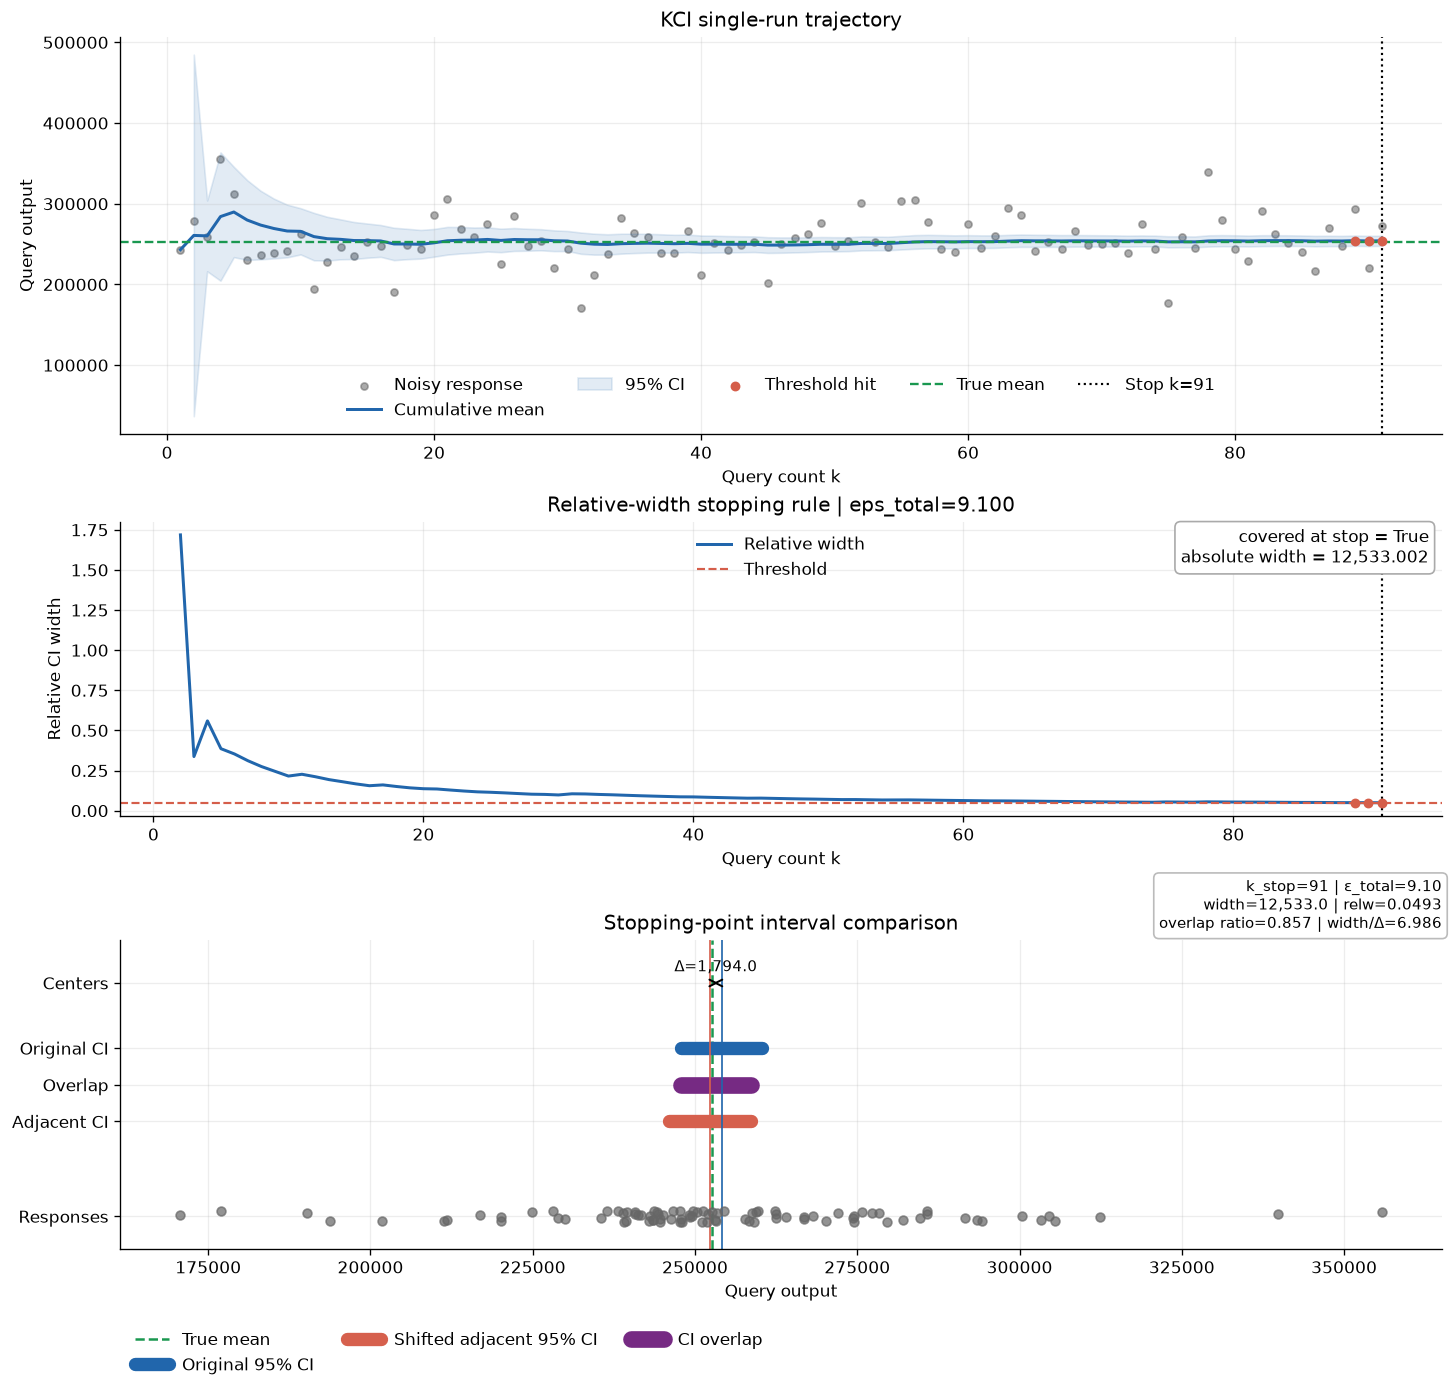

In [19]:
plot_kci_live(kci_history, kci_final,
              save=None);
              # save=OUTPUT_DIR / "kci_single_cardbase_2003.png");

# KCI 반복 실험(평균적인 엡실론 보기 위함)

In [50]:
# @title
def run_kci_repeated(data, eps, threshold, streak_required, reps=10,
                     maxq=MAXQ, seed0=2026, alpha=ALPHA):
    """동일한 KCI 조건에서 seed만 바꾸어 반복한다."""
    finals, histories = [], []
    for rep in range(1, reps + 1):
        seed = int(seed0 + rep - 1)
        history, final = run_kci_live(data, eps, threshold, streak_required,
                                      maxq=maxq, seed=seed, alpha=alpha)
        final = dict(final)
        final.update({"rep": rep, "seed": seed})
        finals.append(final)
        h = history.copy()
        h.insert(0, "rep", rep)
        h.insert(1, "seed", seed)
        histories.append(h)
    final_results = pd.DataFrame(finals)
    trajectories = pd.concat(histories, ignore_index=True)
    summary = _summarize_repeated(final_results)
    summary["method"] = "KCI"
    summary["eps"] = eps
    summary["threshold"] = threshold
    summary["streak_required"] = streak_required
    return final_results, trajectories, summary

In [51]:
# trial_results, round_summary, trajectories, final_eps, info = run_inverse_live(
#     DATA["CardBase"], eps=0.1, threshold=0.05, streak_required=3,
#     initial_eps_total=5, step=1.03, success_rate_threshold=0.95,
#     num_runs=500, max_rounds=50, verbose=True)


# === 동일한 조건에서 1000회 반복 실행 ===
kci_final, kci_trajectories, kci_summary = run_kci_repeated(
    DATA["CardBase"], 0.1, 0.05, 3, reps=500,
    maxq=500, seed0=2026, alpha=ALPHA)

In [52]:
print(kci_summary)

   n_reps  k_stop_mean  k_stop_median  k_stop_min  k_stop_max  k_stop_std  \
0     500         61.4           61.0         5.0       113.0   18.657766   

   eps_total_mean  eps_total_median  eps_total_min  eps_total_max  ...  \
0            6.14               6.1            0.5           11.3  ...   

   relative_width_std  covered_mean  covered_median  covered_min  covered_max  \
0            0.002144         0.932             1.0          0.0          1.0   

   covered_std  method  eps  threshold  streak_required  
0     0.251998     KCI  0.1       0.05                3  

[1 rows x 30 columns]


In [ ]:
k95 = np.quantile(kci_final["k_stop"], 0.95, method="inverted_cdf")
eps95 = k95 * 0.1   # eps
print(k95, eps95)

# 95% 분위수에 있다고 해서, 그 ε이 시행의 성공 확률을 95%로 보장하는 것은 아님. 실제 성공률은 시행별로 다름.

90 9.0


# 토탈 엡실론을 입력하고 시행 성공률 계산

In [53]:
import numpy as np
import pandas as pd
from scipy import stats


def _kci_stop_times(true_mean, delta, eps, threshold, streak_required,
                    num_runs, k_cap, seed0=0, alpha=0.05, min_queries=2):
    """
    KCI 정지 규칙을 시행별로 k_cap개 질의까지 시뮬레이션.
    반환: seeds, stop_k(정지 못하면 0), relw 행렬, 누적평균 행렬
    """
    k_cap = int(k_cap)
    seeds = seed0 + np.arange(num_runs)              # 시행 시드 = seed0 + rep - 1
    if k_cap < max(2, min_queries):                  # CI 계산 불가 → 전부 미수렴
        return seeds, np.zeros(num_runs, dtype=int), None, None

    scale = delta / eps
    X = np.empty((num_runs, k_cap))
    for r, s in enumerate(seeds):
        rng = np.random.default_rng(int(s))
        X[r] = true_mean + rng.laplace(0.0, scale, size=k_cap)

    k = np.arange(1, k_cap + 1)
    Y = X - X[:, :1]                                 # 수치 안정용 이동(분산 불변)
    S1 = np.cumsum(Y, axis=1)
    S2 = np.cumsum(Y ** 2, axis=1)
    mean = X[:, :1] + S1 / k

    with np.errstate(divide="ignore", invalid="ignore"):
        var = np.maximum((S2 - S1 ** 2 / k) / (k - 1), 0.0)   # 표본분산(ddof=1)
        tcrit = np.full(k_cap, np.nan)
        tcrit[1:] = stats.t.ppf(1 - alpha / 2, k[1:] - 1)
        moe = tcrit * np.sqrt(var / k)
        relw = 2 * moe / np.abs(mean)

    hit = relw < threshold                           # NaN → False
    hit[:, :max(min_queries, 2) - 1] = False

    streak = np.zeros(num_runs, dtype=int)
    stop_k = np.zeros(num_runs, dtype=int)
    for j in range(k_cap):
        streak = np.where(hit[:, j], streak + 1, 0)
        newly = (stop_k == 0) & (streak >= streak_required)
        stop_k[newly] = j + 1
    return seeds, stop_k, relw, mean


def _wilson(n_succ, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = n_succ / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (c - h, c + h)


def kci_success_under_budget(true_mean, delta, eps, eps_total, threshold,
                             streak_required, num_runs=1000, seed0=0,
                             alpha=0.05, maxq=200, min_queries=2,
                             return_trials=True):
    """
    총예산 eps_total 하에서 KCI 시행 중 정지 규칙을 만족(수렴)한 횟수·비율 계산.
    """
    k_max = int(np.floor(eps_total / eps + 1e-9))    # 3.0/0.1 = 29.999... 방지
    k_eval = min(k_max, maxq)

    seeds, stop_k, relw, mean = _kci_stop_times(
        true_mean, delta, eps, threshold, streak_required,
        num_runs, k_eval, seed0, alpha, min_queries)

    conv = stop_k > 0
    n_conv = int(conv.sum())
    spent = np.where(conv, stop_k * eps, k_eval * eps)
    lo, hi = _wilson(n_conv, num_runs)

    summary = {
        "eps_total_input": eps_total,
        "k_max": k_max,
        "k_eval": k_eval,
        "capped_by_maxq": k_max > maxq,
        "num_runs": num_runs,
        "n_converged": n_conv,
        "n_not_converged": num_runs - n_conv,
        "success_rate": n_conv / num_runs,
        "success_rate_ci95": (lo, hi),
        "mean_eps_spent_converged": float(spent[conv].mean()) if n_conv else np.nan,
        "median_eps_spent_converged": float(np.median(spent[conv])) if n_conv else np.nan,
    }

    if not return_trials:
        return summary, None

    idx = np.arange(num_runs)
    last = np.where(conv, stop_k, k_eval) - 1
    trials = pd.DataFrame({
        "trial": idx + 1,
        "seed": seeds,
        "converged": conv,
        "stop_k": np.where(conv, stop_k, np.nan),
        "eps_spent": spent,
        "final_relw": relw[idx, last] if relw is not None else np.nan,
        "final_mean": mean[idx, last] if mean is not None else np.nan,
    })
    return summary, trials


def kci_success_sweep(true_mean, delta, eps, eps_totals, threshold,
                      streak_required, num_runs=1000, seed0=0,
                      alpha=0.05, maxq=200, min_queries=2):
    """
    maxq까지 한 번만 시뮬레이션하고, 여러 총예산에 대한 수렴 비율을 한꺼번에 계산.
    """
    _, stop_k, _, _ = _kci_stop_times(
        true_mean, delta, eps, threshold, streak_required,
        num_runs, maxq, seed0, alpha, min_queries)

    rows = []
    for B in eps_totals:
        k_max = int(np.floor(B / eps + 1e-9))
        k_eval = min(k_max, maxq)
        conv = (stop_k > 0) & (stop_k <= k_eval)
        n_conv = int(conv.sum())
        lo, hi = _wilson(n_conv, num_runs)
        rows.append({
            "eps_total": B, "k_max": k_max, "capped_by_maxq": k_max > maxq,
            "n_converged": n_conv, "success_rate": n_conv / num_runs,
            "ci95_lo": lo, "ci95_hi": hi,
            "mean_eps_spent_converged":
                float((stop_k[conv] * eps).mean()) if n_conv else np.nan,
        })
    return pd.DataFrame(rows)


In [54]:
# true_mean, delta는 기존 run_kci_overlap_live에 넣던 값 그대로 (CardBase: Δ=1794)
summary, trials = kci_success_under_budget(
    true_mean=TRUE_MEAN, delta=1794, eps=0.1, eps_total=6.1,
    threshold=0.05, streak_required=3, num_runs=500, seed0=100_000)
print(summary)

# sweep = kci_success_sweep(
#     true_mean=TRUE_MEAN, delta=1794, eps=0.1,
#     eps_totals=np.arange(2.0, 20.01, 0.5),
#     threshold=0.05, streak_required=3, num_runs=5000, seed0=100_000)

{'eps_total_input': 6.1, 'k_max': 61, 'k_eval': 61, 'capped_by_maxq': False, 'num_runs': 500, 'n_converged': 225, 'n_not_converged': 275, 'success_rate': 0.45, 'success_rate_ci95': (np.float64(0.4069388734465702), np.float64(0.4938235884065202)), 'mean_eps_spent_converged': 4.723111111111112, 'median_eps_spent_converged': 5.0}


## CAPRI 방식 역산 모델 유틸리티 함수

> 대표 시행 선택 (ε 기준 중앙 순위)

In [55]:
def select_representative_trial(trial_finals):
    """actual_eps_total을 정렬해 가운데 순위의 시행을 고른다(짝수면 작은 쪽).

    미수렴(NaN) 시행은 순위에서 제외한다. 전부 미수렴이면 None.
    반환: 대표 시행의 행(Series)
    """
    v = trial_finals["actual_eps_total"].astype(float)
    finite = v[np.isfinite(v)]
    if len(finite) == 0:
        return None
    pos = (len(finite) - 1) // 2                 # 짝수면 작은 쪽
    target = float(finite.sort_values().iloc[pos])
    return trial_finals[np.isclose(v, target)].iloc[0]

> 시각화 헬퍼

In [56]:
def _last_round_block(g):
    """시행 g의 마지막 라운드(= 성공 라운드) 블록을 잘라낸다.

    round 열이 없어도 동작한다: k가 1로 리셋되는 마지막 지점부터 끝까지.
    """
    k = g["k"].to_numpy()
    starts = np.where(k == 1)[0]
    return g.iloc[starts[-1]:] if len(starts) else g

> 시행 집계 시각화(1부)

In [57]:
def plot_inverse_runs_summary(trial_finals, round_results, trajectories,
                              rep_row=None, final_eps=None, save=None):
    """개편판 역산 — 시행 집계 (1부). round 열에 의존하지 않음."""
    blue, red, green, gray = "#2166AC", "#D55E4A", "#1A9850", "#666666"

    # --- 입력 점검: 없으면 원인이 드러나게 즉시 실패 ---
    need_tf = {"rep", "actual_eps_total"}
    need_rr = {"rep", "round", "round_success", "k_max", "candidate_eps_total"}
    need_tr = {"rep", "k", "relative_width"}
    for name, df, need in [("trial_finals", trial_finals, need_tf),
                           ("round_results", round_results, need_rr),
                           ("trajectories", trajectories, need_tr)]:
        missing = need - set(df.columns)
        if missing:
            raise KeyError(f"{name}에 열이 없습니다: {sorted(missing)} "
                           f"(실제 열: {sorted(df.columns)})")

    fig = plt.figure(figsize=(13, 9), constrained_layout=True)
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.15])
    ax0 = fig.add_subplot(gs[0, 0])
    ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[1, :])

    # ---------------- ax0 : ε 분포 ----------------
    v = trial_finals["actual_eps_total"].astype(float).to_numpy()
    vals = v[np.isfinite(v)]
    if len(vals):
        jit = np.linspace(-.12, .12, len(vals)) if len(vals) > 1 else np.array([0.0])
        q1, med, q3 = np.quantile(vals, [0.25, .5, .75])
        mean_v, p95 = float(np.mean(vals)), float(np.quantile(vals, .95))
        ax0.plot([0, 0], [q1, q3], color=blue, lw=10, solid_capstyle="round", alpha=.30)
        ax0.scatter(jit, vals, color=blue, s=30, edgecolor="white", lw=.5,
                    zorder=3, label=f"trial ε (n={len(vals)})")
        ax0.scatter([0], [med], facecolor="white", edgecolor="black", s=70,
                    zorder=4, label=f"median={med:.2f}")
        ax0.scatter([0], [mean_v], marker="D", facecolor="black", edgecolor="white",
                    s=55, zorder=5, label=f"mean={mean_v:.2f}")
        ax0.axhline(p95, color=red, ls=":", lw=1.5, label=f"p95={p95:.2f}")
        if final_eps is not None:
            ax0.axhline(float(final_eps), color=green, ls="--", lw=1.8,
                        label=f"final ε={float(final_eps):.2f}")
        if rep_row is not None:
            ax0.scatter([0], [float(rep_row["actual_eps_total"])], marker="*",
                        color=red, s=280, zorder=6, edgecolor="white", lw=.8,
                        label=f"representative={float(rep_row['actual_eps_total']):.2f}")
        ax0.set_xlim(-.5, .5); ax0.set_xticks([])
        ax0.set_ylabel("Actual total epsilon")
        ax0.set_title("Trial epsilon distribution")
        ax0.legend(frameon=False, fontsize=8, loc="upper left")
        ax0.grid(axis="y", alpha=.25)
    else:
        ax0.set_title("Trial epsilon distribution (no converged trial)")

    # ---------------- ax1 : 수렴 라운드 ----------------
    succ = round_results[round_results["round_success"] == True]
    if len(succ):
        counts = succ.groupby("round").size()
        ax1.bar(counts.index, counts.values, color="#762A83", alpha=.8)
        for r, c in counts.items():
            ax1.text(r, c, str(int(c)), ha="center", va="bottom", fontsize=8)
        ax1.set_title(f"Converged round (mode = round {int(counts.idxmax())})")
    else:
        ax1.set_title("Converged round (none)")
    ax1.set_xlabel("Round"); ax1.set_ylabel("Number of trials")
    ax1.grid(axis="y", alpha=.25)

    # ---------------- ax2 : 궤적 중첩 ----------------
    rep_id = None if rep_row is None else int(rep_row["rep"])
    collected = []

    for rep, g in trajectories.groupby("rep"):
        block = _last_round_block(g)                  # ← round 열 불필요
        rw = block["relative_width"].astype(float)
        collected.append(rw[np.isfinite(rw)].to_numpy())
        if rep != rep_id:
            ax2.plot(block["k"], rw, color=gray, lw=0.9, alpha=.30)

    if rep_id is not None and rep_id in set(trajectories["rep"]):
        block = _last_round_block(trajectories[trajectories["rep"] == rep_id])
        ax2.plot(block["k"], block["relative_width"].astype(float), color=red,
                 lw=2.4, zorder=4, label=f"representative (rep={rep_id})")
        ax2.scatter(block["k"].iloc[-1], float(block["relative_width"].iloc[-1]),
                    color=red, s=70, zorder=5, edgecolor="white")

    thr = float(trial_finals["threshold"].iloc[0])    # ← 궤적이 아니라 최종 결과에서
    ax2.axhline(thr, color=blue, ls="--", lw=1.5, label=f"threshold={thr}")
    flat = np.concatenate(collected) if collected else np.array([])
    flat = flat[np.isfinite(flat)]
    if len(flat):
        ax2.set_ylim(0, max(float(np.quantile(flat, .90)) * 1.2, thr * 5))
    ax2.set_xlabel("Within-round query count k")
    ax2.set_ylabel("Relative CI width")
    ax2.set_title("Relative-width trajectories at each trial's successful round "
                  f"(n={len(collected)} trials)")
    ax2.legend(frameon=False, fontsize=8)
    ax2.grid(alpha=.25)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

> 대표 시행 상세 시각화(2부)

In [58]:
def plot_inverse_trial_detail(trial_finals, round_results, trajectories, rep,
                              save=None):
    """개편판 역산 — 지정 시행 1개의 상세 (2부). round 열에 의존하지 않음."""
    blue, red, green, gray, purple = "#2166AC", "#D55E4A", "#1A9850", "#666666", "#762A83"

    row = trial_finals[trial_finals["rep"] == rep]
    if row.empty:
        raise ValueError(f"rep={rep} 시행이 trial_finals에 없습니다.")
    row = row.iloc[0]

    rs = round_results[round_results["rep"] == rep].sort_values("round").copy()
    succ = rs[rs["round_success"] == True]
    if succ.empty:
        raise ValueError(f"rep={rep} 시행은 수렴하지 않아 그릴 성공 라운드가 없습니다.")
    success_round = int(succ["round"].iloc[0])

    traj = trajectories[trajectories["rep"] == rep].copy()
    if traj.empty:
        raise ValueError(f"rep={rep} 시행의 궤적이 trajectories에 없습니다.")
    h = _last_round_block(traj)                       # ← round 열 불필요

    final = dict(row)
    final["eps_total"] = float(final["actual_eps_total"])
    final["k"] = int(final["k_stop"])
    n_last = int(h["streak_count"].iloc[-1])

    fig = plt.figure(figsize=(13, 12), constrained_layout=True)
    gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 1.05])
    ax0 = fig.add_subplot(gs[0, 0]); ax1 = fig.add_subplot(gs[0, 1])
    ax2 = fig.add_subplot(gs[1, 0]); ax3 = fig.add_subplot(gs[1, 1])
    ax4 = fig.add_subplot(gs[2, :])

    ax0.plot(rs["round"], rs["candidate_eps_total"], "o-", color=blue, lw=1.8)
    ax0.scatter(succ["round"], succ["candidate_eps_total"], color=green, s=70,
                zorder=4, label="Success")
    ax0.set_title("Candidate budget by round")
    ax0.set_xlabel("Round"); ax0.set_ylabel("Candidate total epsilon")
    ax0.legend(frameon=False)

    ax1.plot(rs["round"], rs["k_max"], "o-", color=purple, lw=1.8, label="k_max")
    ax1.scatter(rs["round"], rs["k_stop"], color=green, s=45, zorder=3, label="k_stop")
    ax1.axvline(success_round, color="black", ls=":", lw=1.3)
    ax1.set_title("Allowed and actual stopping query counts")
    ax1.set_xlabel("Round"); ax1.set_ylabel("Query count")
    ax1.legend(frameon=False, fontsize=8)

    valid = h["k"] >= 2
    ax2.scatter(h["k"], h["response"], color=gray, s=18, alpha=.55,
                label="Noisy response")
    ax2.plot(h["k"], h["cumulative_mean"], color=blue, lw=1.8, label="Cumulative mean")
    ax2.fill_between(h.loc[valid, "k"].to_numpy(), h.loc[valid, "ci_lo"].to_numpy(),
                     h.loc[valid, "ci_hi"].to_numpy(), color=blue, alpha=.13,
                     label="95% CI")
    ax2.axhline(final["true_mean"], color=green, ls="--", label="True mean")
    ax2.set_title(f"Representative trial (rep={rep}, round={success_round}, "
                  f"k={final['k']})")
    ax2.set_xlabel("Within-round query count k"); ax2.set_ylabel("Query output")
    ax2.legend(frameon=False, fontsize=8)

    ax3.plot(h["k"], h["relative_width"], color=blue, lw=1.8, label="Relative width")
    ax3.axhline(final["threshold"], color=red, ls="--", label="Threshold")
    tail = h.tail(n_last)
    if len(tail):
        ax3.scatter(tail["k"], tail["relative_width"], color=red, s=35, zorder=3,
                    label=f"Last {n_last} checks")
    ax3.set_title(f"Final round check | actual eps={final['actual_eps_total']:.2f}")
    ax3.set_xlabel("Within-round query count k"); ax3.set_ylabel("Relative CI width")
    ax3.legend(frameon=False, fontsize=8)

    _plot_stop_overlap(ax4, h, final)

    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

# 실제 개선된 역산 실행

대표 시행: rep=38 | k_stop=31 | ε=3.10 | rounds=16
최종 ε(평균)=2.97


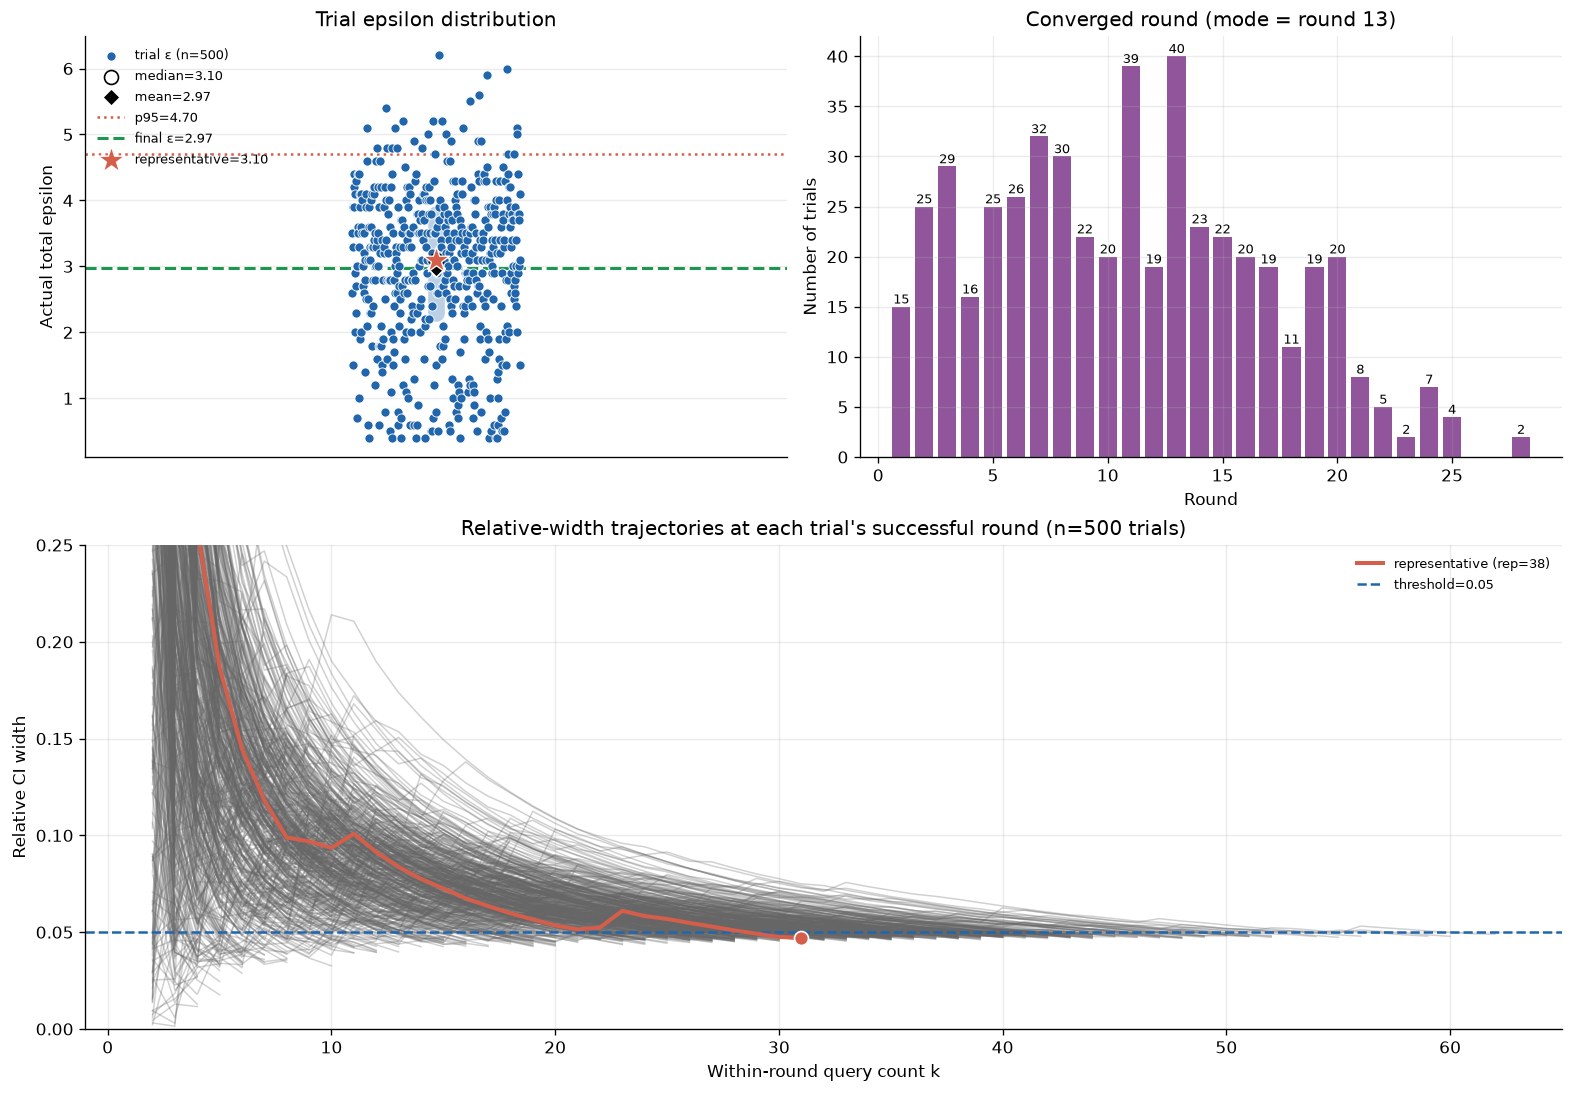

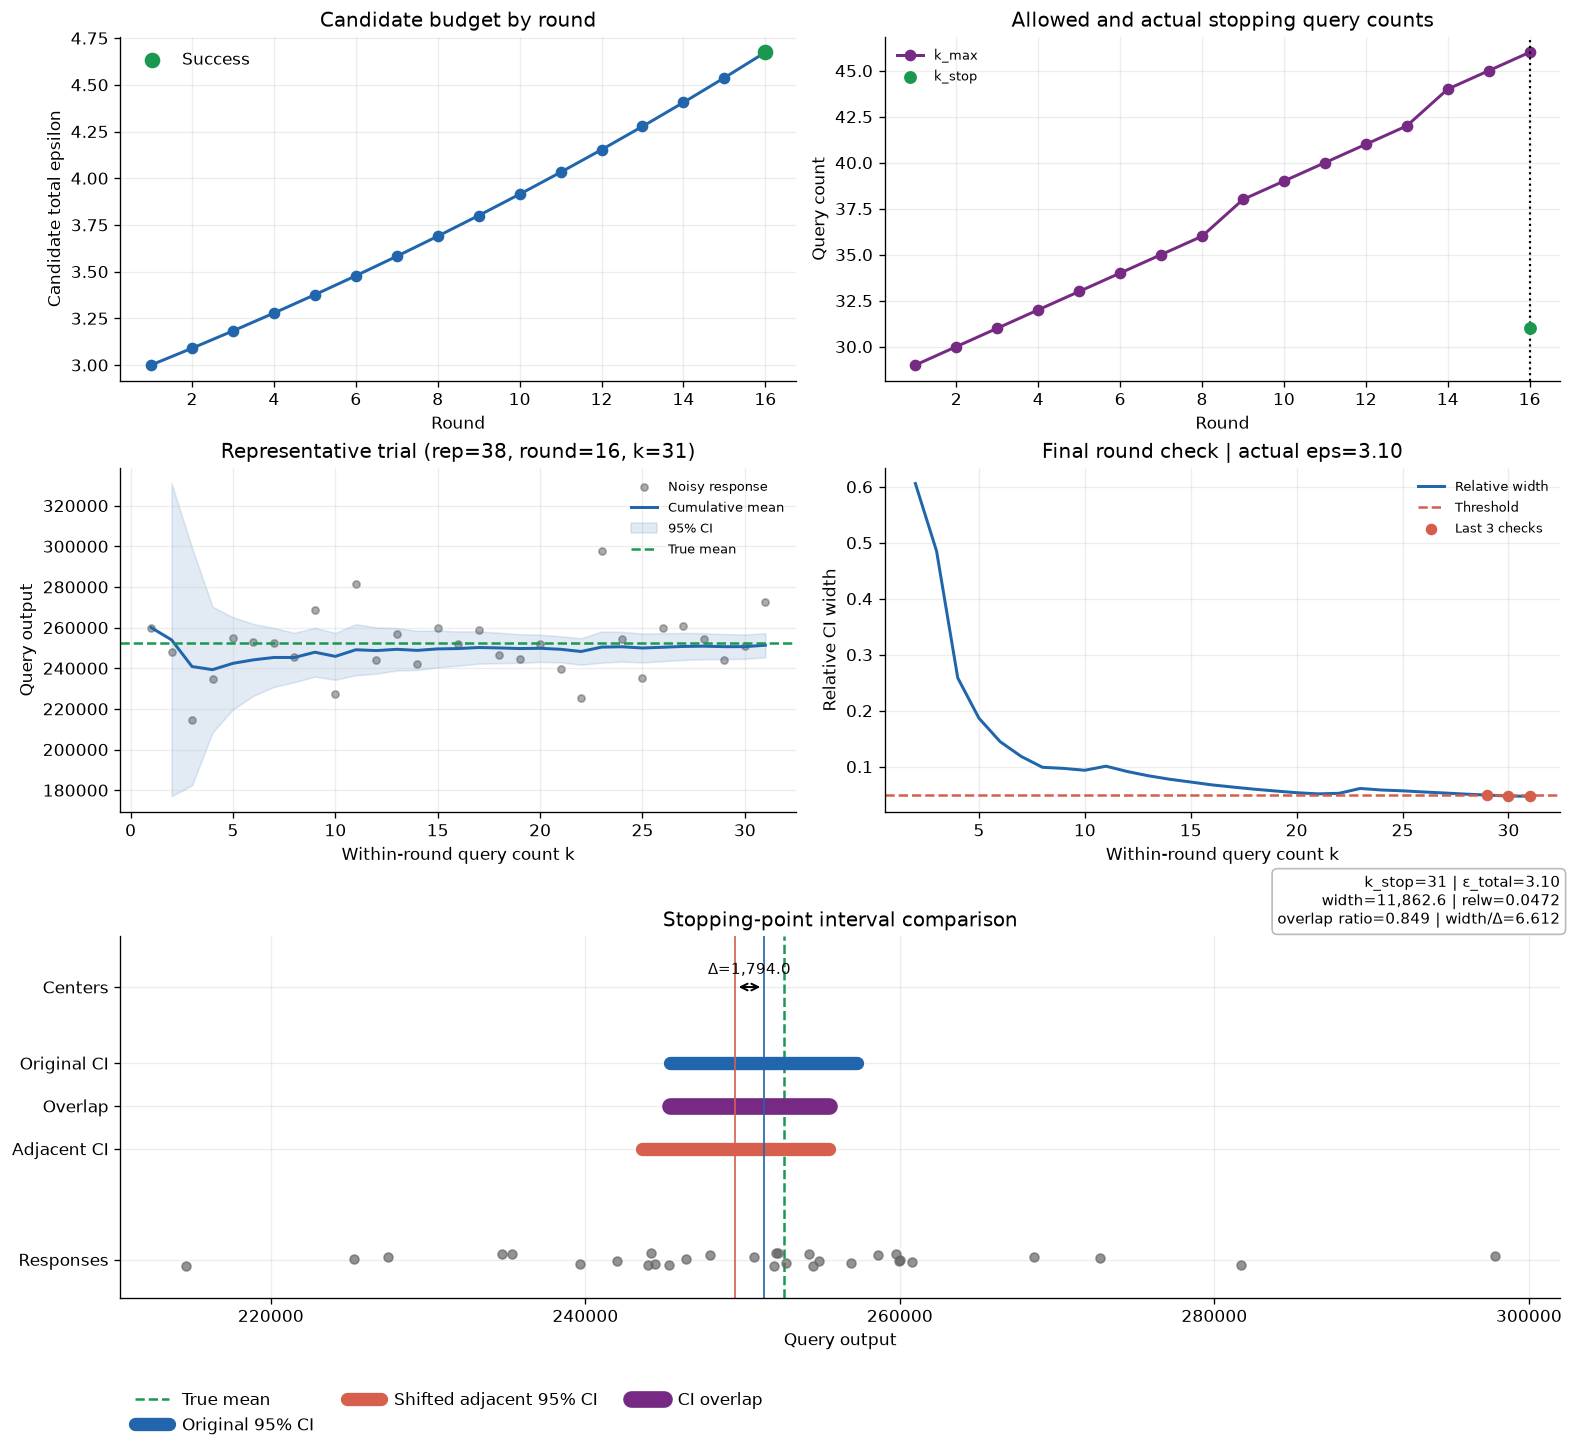

In [ ]:
# ---- 개편판 역산 1회 수행 ----
trial_finals, round_results, trajectories, final_eps = run_inverse_live(
    DATA["CardBase"],
    eps=0.1, threshold=0.05, streak_required=3,
    initial_eps_total=3, step=1.03,
    num_runs=500, max_rounds=50, maxq=MAXQ,
    seed0=2025, eps_decimals=2, verbose=False,
)

# ---- 대표 시행 선택 ----
rep_row = select_representative_trial(trial_finals)
print(f"대표 시행: rep={int(rep_row['rep'])} | k_stop={int(rep_row['k_stop'])} | "
      f"ε={float(rep_row['actual_eps_total']):.2f} | rounds={int(rep_row['n_rounds'])}")
print(f"최종 ε(평균)={final_eps}")

# ---- 1부: 집계 ----
plot_inverse_runs_summary(trial_finals, round_results, trajectories,
                          rep_row=rep_row, final_eps=final_eps);

# ---- 2부: 대표 시행 상세 ----
plot_inverse_trial_detail(trial_finals, round_results, trajectories,
                          rep=int(rep_row["rep"]));

In [48]:
final_results, trajectories, summary = run_kci_repeated(
    DATA["CardBase"], eps=0.1, threshold=0.05, streak_required=3, 
    reps=50, maxq=MAXQ, seed0=2025)

In [49]:
# print(final_results.head())
epsilon_summary = final_results["eps_total"].mean()
print(epsilon_summary)

6.292000000000001


# 261106 새로운 방법론 (CAPRI 엄격하게 따름)

In [59]:
# ============================================================================
# 개편판 v2: CAPRI형 역산 알고리즘
#   라운드(바깥) : 후보 ε_total → k_max = floor(ε_total / ε)
#   시행(안쪽)   : num_runs번 독립 시행 (시행 내 step 재시도 없음)
#   판정         : 성공 비율 ≥ success_rate_threshold 이면 합격
#   출력         : 합격 라운드에서 '성공한 시행'의 실제 소모 ε 평균 (기대 소모량)
#                  + 합격 라운드의 k_eval·ε (보장 예산)은 info로 함께 반환
# ============================================================================
def _simulate_trial(data, eps, k_max, threshold, streak_required, alpha, rng,
                    keep_rows=False):
    """시행 1회: 질의를 1건씩 추가하며 streak 판정. step 재시도 없음."""
    scale = data["delta"] / eps
    responses, rows = [], []
    streak = 0
    stopped_k, last = None, None

    for k in range(1, k_max + 1):
        responses.append(float(data["true_mean"] + rng.laplace(0.0, scale)))
        row = _statistics(responses, data["true_mean"], alpha)
        row.update(_overlap_from_ci(row["ci_lo"], row["ci_hi"], data["delta"]))

        hit = bool(np.isfinite(row["relative_width"])
                   and row["relative_width"] < threshold)
        streak = streak + 1 if hit else 0
        row.update({"query_k": k, "hit": hit, "streak_count": streak,
                    "actual_eps_total": eps * k})
        if keep_rows:
            rows.append(row)
        last = row

        if streak >= streak_required:
            stopped_k = k
            break

    return stopped_k, last, rows


def run_inverse_live(data, eps, threshold, streak_required,
                     initial_eps_total, step, success_rate_threshold=0.95,
                     num_runs=50, max_rounds=20, maxq=MAXQ, seed0=2026,
                     alpha=ALPHA, eps_decimals=2, keep_trajectories="final",
                     verbose=False):
    """CAPRI형 역산 알고리즘의 단일 수행.

    반환: (trial_results, round_summary, trajectories, final_eps, info)
      - trial_results : 마지막(합격/종료) 라운드의 시행별 결과
      - round_summary : 라운드별 후보 예산, k_eval, 성공 수, 성공 비율
      - trajectories  : 질의 시점 궤적 (keep_trajectories 설정에 따름)
      - final_eps     : 성공 시행의 실제 소모 ε 평균 (기대 소모량, 반올림)
      - info          : status, eps_total_guaranteed(보장 예산), success_rate 등
    """
    _validate_inputs(eps, threshold, streak_required, maxq)
    if initial_eps_total <= 0:
        raise ValueError("initial_eps_total은 0보다 커야 합니다.")
    if step <= 1:
        raise ValueError("step은 1보다 커야 합니다.")
    if max_rounds < 1:
        raise ValueError("max_rounds는 1 이상이어야 합니다.")
    if num_runs < 1:
        raise ValueError("num_runs는 1 이상이어야 합니다.")
    if not (0 < success_rate_threshold <= 1):
        raise ValueError("success_rate_threshold는 (0, 1] 범위여야 합니다.")
    if keep_trajectories not in ("none", "final", "all"):
        raise ValueError("keep_trajectories는 'none', 'final', 'all' 중 하나입니다.")

    keep_rows = keep_trajectories != "none"
    round_rows, all_traj = [], []
    last_trials, last_traj, last_round = None, [], None
    status = "max_rounds_exceeded"
    eps_total = float(initial_eps_total)

    # ---------------------------------------------------------------- 라운드
    for round_no in range(1, max_rounds + 1):
        candidate = float(eps_total)
        k_max = int(candidate // eps)

        if k_max < 2:                       # 판정 불가 → 성공 비율 0으로 보고 증가
            round_rows.append({
                "round": round_no, "candidate_eps_total": candidate,
                "k_max": k_max, "k_eval": k_max, "eps_total_eval": eps * k_max,
                "n_success": 0, "success_rate": 0.0, "passed": False,
                "maxq_reached": False, "note": "k_max<2",
            })
            eps_total *= step
            continue

        k_eval = min(k_max, maxq)
        maxq_reached = k_max >= maxq

        # ------------------------------------------------------------ 시행
        trials, traj = [], []
        for rep in range(1, num_runs + 1):
            seed = int(seed0 + rep - 1)
            round_seed = int(seed + round_no * 1_000_003)   # 라운드마다 새 시드
            rng = np.random.default_rng(round_seed)

            stopped_k, last, rows = _simulate_trial(
                data, eps, k_eval, threshold, streak_required, alpha, rng,
                keep_rows=keep_rows)
            ok = stopped_k is not None

            trials.append({
                "method": "INVERSE", "round": round_no, "rep": rep,
                "seed": seed, "round_seed": round_seed,
                "eps": float(eps), "k_eval": k_eval,
                "eps_total_eval": float(eps * k_eval),
                "success": ok,
                "k_stop": int(stopped_k) if ok else np.nan,
                "actual_eps_total": float(eps * stopped_k) if ok else np.nan,
                "cumulative_mean": last["cumulative_mean"],
                "ci_width": last["ci_width"],
                "relative_width": last["relative_width"],
                "covered": last["covered"],
                "threshold": float(threshold),
                "streak_required": int(streak_required),
            })
            if keep_rows and rows:
                df = pd.DataFrame(rows)
                df["round"], df["rep"], df["round_seed"] = round_no, rep, round_seed
                df["success"] = ok
                traj.append(df)

        trials_df = pd.DataFrame(trials)
        n_success = int(trials_df["success"].sum())
        rate = n_success / num_runs
        passed = rate >= success_rate_threshold

        round_rows.append({
            "round": round_no, "candidate_eps_total": candidate,
            "k_max": k_max, "k_eval": k_eval, "eps_total_eval": eps * k_eval,
            "n_success": n_success, "success_rate": rate, "passed": passed,
            "maxq_reached": maxq_reached, "note": "",
        })
        if keep_trajectories == "all":
            all_traj.extend(traj)
        last_trials, last_traj, last_round = trials_df, traj, round_rows[-1]

        if verbose:
            print(f"[round {round_no:>3}] cand={candidate:>8.4f} | k_eval={k_eval:>4} | "
                  f"success={n_success}/{num_runs} ({rate:.3f}) | pass={passed}")

        if passed:
            status = "converged"
            break
        if maxq_reached:                    # maxq까지 가도 임계 미달
            status = "maxq_reached"
            break
        eps_total *= step

    # ---------------------------------------------------------------- 출력
    round_summary = pd.DataFrame(round_rows)
    trial_results = last_trials if last_trials is not None else pd.DataFrame()

    if keep_trajectories == "final" and last_traj:
        trajectories = pd.concat(last_traj, ignore_index=True)
    elif keep_trajectories == "all" and all_traj:
        trajectories = pd.concat(all_traj, ignore_index=True)
    else:
        trajectories = pd.DataFrame()

    if status == "converged":
        succ = trial_results.loc[trial_results["success"], "actual_eps_total"]
        final_eps_raw = float(succ.mean())
        final_eps = round(final_eps_raw, eps_decimals)
        eps_total_guaranteed = float(last_round["eps_total_eval"])
    else:
        final_eps_raw = final_eps = eps_total_guaranteed = np.nan

    info = {
        "status": status,
        "final_eps": final_eps,                       # 기대 소모량 (출력)
        "final_eps_raw": final_eps_raw,
        "eps_total_guaranteed": eps_total_guaranteed, # 보장 예산
        "success_rate": last_round["success_rate"] if last_round else np.nan,
        "n_success": last_round["n_success"] if last_round else 0,
        "num_runs": num_runs,
        "rounds_used": len(round_rows),
        "success_rate_threshold": success_rate_threshold,
        "eps": float(eps), "threshold": float(threshold),
        "streak_required": int(streak_required),
    }

    if verbose:
        print(f"\n[요약] status={status} | 성공 비율={info['success_rate']} | "
              f"기대 소모량 ε={final_eps} | 보장 예산 ε={eps_total_guaranteed}")

    return trial_results, round_summary, trajectories, final_eps, info

> 시각화 함수

In [60]:
import matplotlib.pyplot as plt

def plot_inverse_search(round_summary, info, ax=None):
    """① 라운드별 후보 예산 대비 성공 비율."""
    ax = ax or plt.subplots(figsize=(5, 3.5))[1]
    rs = round_summary
    ax.plot(rs["eps_total_eval"], rs["success_rate"], "-o", ms=4, lw=1,
            color="tab:blue", label="Success rate per round")
    ax.axhline(info["success_rate_threshold"], ls="--", color="gray",
               label=f"τ = {info['success_rate_threshold']}")
    if info["status"] == "converged":
        acc = rs[rs["passed"]].iloc[-1]
        ax.plot(acc["eps_total_eval"], acc["success_rate"], "*", ms=14,
                color="tab:red", label=f"Accepted: ε_total = {acc['eps_total_eval']:.2f}")
    ax.set_xlabel("Candidate total budget (k_eval · ε)")
    ax.set_ylabel("Success rate")
    ax.set_ylim(-0.03, 1.03)
    ax.set_title("Budget search")
    ax.legend(fontsize=8, loc="lower right")
    return ax


def plot_inverse_consumption(trial_results, info, ax=None, seed=0):
    """② 합격 라운드의 실제 소모 ε: ECDF(전체 시행 기준) + strip plot."""
    ax = ax or plt.subplots(figsize=(5, 3.5))[1]
    n = len(trial_results)
    vals = np.sort(trial_results.loc[trial_results["success"],
                                     "actual_eps_total"].to_numpy(float))
    if vals.size == 0:
        ax.text(0.5, 0.5, "No successful trials", ha="center", transform=ax.transAxes)
        return ax

    # ECDF: 분모 = 전체 시행 수 → 곡선의 최종 높이 = 성공 비율
    y = np.arange(1, vals.size + 1) / n
    ax.step(np.r_[vals[0], vals], np.r_[0, y], where="post",
            color="tab:blue", lw=1.5, label="ECDF (all trials)")

    # strip plot (개별 시행)
    rng = np.random.default_rng(seed)
    ax.scatter(vals, -0.06 + rng.uniform(-0.02, 0.02, vals.size),
               s=6, alpha=0.4, color="tab:blue")

    mean_eps = info["final_eps_raw"]
    guar = info["eps_total_guaranteed"]
    p_mean = np.sum(vals <= mean_eps) / n
    ax.axvline(mean_eps, color="tab:green", ls="-",
               label=f"Expected consumption (output) = {mean_eps:.2f}  [{p_mean:.2f}]")
    ax.axvline(guar, color="tab:red", ls="--",
               label=f"Guaranteed budget = {guar:.2f}  [{info['success_rate']:.2f}]")
    ax.axhline(info["success_rate_threshold"], color="gray", ls=":", lw=1)

    ax.set_xlabel("Actual consumed ε (ε · k_stop)")
    ax.set_ylabel("Fraction of trials finished")
    ax.set_ylim(-0.1, 1.03)
    ax.set_title(f"Consumed budget (failed: {n - vals.size}/{n})")
    ax.legend(fontsize=7, loc="upper left")
    return ax


def plot_inverse_trajectories(trajectories, info, n_show=30, ax=None, seed=0):
    """③ 합격 라운드의 상대폭 궤적 (일부 시행만 표시)."""
    ax = ax or plt.subplots(figsize=(5, 3.5))[1]
    if trajectories.empty:
        ax.text(0.5, 0.5, "No trajectories stored", ha="center", transform=ax.transAxes)
        return ax
    tr = trajectories[trajectories["round"] == trajectories["round"].max()]
    reps = tr["rep"].unique()
    rng = np.random.default_rng(seed)
    show = rng.choice(reps, size=min(n_show, len(reps)), replace=False)

    for rep in show:
        d = tr[tr["rep"] == rep]
        ok = bool(d["success"].iloc[0])
        ax.plot(d["query_k"], d["relative_width"], lw=0.8, alpha=0.5,
                color="tab:blue" if ok else "tab:red")
        if ok:
            ax.plot(d["query_k"].iloc[-1], d["relative_width"].iloc[-1],
                    "o", ms=3, color="black")

    ax.axhline(info["threshold"], color="gray", ls="--",
               label=f"threshold = {info['threshold']}")
    ax.set_yscale("log")
    ax.set_xlabel("Number of queries k")
    ax.set_ylabel("Relative CI width")
    ax.set_title(f"Trajectories (streak = {info['streak_required']}; "
                 f"blue: success, red: fail)")
    ax.legend(fontsize=8)
    return ax


def plot_inverse_summary(trial_results, round_summary, trajectories, info,
                         n_show=30, figsize=(15, 4)):
    """①②③을 한 줄로."""
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    plot_inverse_search(round_summary, info, ax=axes[0])
    plot_inverse_consumption(trial_results, info, ax=axes[1])
    plot_inverse_trajectories(trajectories, info, n_show=n_show, ax=axes[2])
    fig.tight_layout()
    return fig


In [61]:
trial_results, round_summary, trajectories, final_eps, info = run_inverse_live(
    DATA["CardBase"], eps=0.1, threshold=0.05, streak_required=3,
    initial_eps_total=5, step=1.03, success_rate_threshold=0.95,
    num_runs=500, max_rounds=50, verbose=True)

[round   1] cand=  5.0000 | k_eval=  49 | success=92/500 (0.184) | pass=False
[round   2] cand=  5.1500 | k_eval=  51 | success=126/500 (0.252) | pass=False
[round   3] cand=  5.3045 | k_eval=  53 | success=145/500 (0.290) | pass=False
[round   4] cand=  5.4636 | k_eval=  54 | success=133/500 (0.266) | pass=False
[round   5] cand=  5.6275 | k_eval=  56 | success=168/500 (0.336) | pass=False
[round   6] cand=  5.7964 | k_eval=  57 | success=184/500 (0.368) | pass=False
[round   7] cand=  5.9703 | k_eval=  59 | success=195/500 (0.390) | pass=False
[round   8] cand=  6.1494 | k_eval=  61 | success=241/500 (0.482) | pass=False
[round   9] cand=  6.3339 | k_eval=  63 | success=258/500 (0.516) | pass=False
[round  10] cand=  6.5239 | k_eval=  65 | success=267/500 (0.534) | pass=False
[round  11] cand=  6.7196 | k_eval=  67 | success=317/500 (0.634) | pass=False
[round  12] cand=  6.9212 | k_eval=  69 | success=319/500 (0.638) | pass=False
[round  13] cand=  7.1288 | k_eval=  71 | success=349

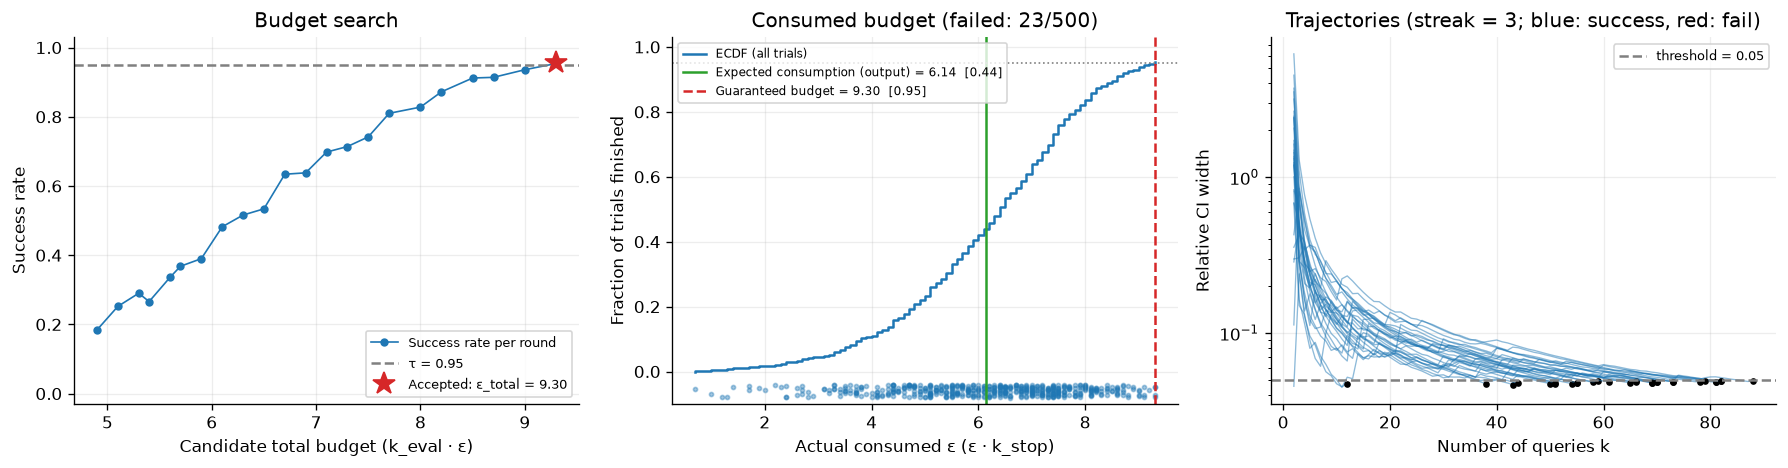

In [62]:
fig = plot_inverse_summary(trial_results, round_summary, trajectories, info)

In [63]:
# true_mean, delta는 기존 run_kci_overlap_live에 넣던 값 그대로 (CardBase: Δ=1794)
summary, trials = kci_success_under_budget(
    true_mean=TRUE_MEAN, delta=1794, eps=0.1, eps_total=9.3,
    threshold=0.05, streak_required=3, num_runs=500, seed0=100_000)
print(summary)

{'eps_total_input': 9.3, 'k_max': 93, 'k_eval': 93, 'capped_by_maxq': False, 'num_runs': 500, 'n_converged': 478, 'n_not_converged': 22, 'success_rate': 0.956, 'success_rate_ci95': (np.float64(0.9342800855801577), np.float64(0.9707662623196583)), 'mean_eps_spent_converged': 6.1587866108786615, 'median_eps_spent_converged': 6.300000000000001}


In [66]:
# true_mean, delta는 기존 run_kci_overlap_live에 넣던 값 그대로 (CardBase: Δ=1794)
summary, trials = kci_success_under_budget(
    true_mean=TRUE_MEAN, delta=1794, eps=0.1, eps_total=9.2,
    threshold=0.05, streak_required=3, num_runs=500, seed0=100_000)
print(summary)

{'eps_total_input': 9.2, 'k_max': 92, 'k_eval': 92, 'capped_by_maxq': False, 'num_runs': 500, 'n_converged': 473, 'n_not_converged': 27, 'success_rate': 0.946, 'success_rate_ci95': (np.float64(0.9225729387555679), np.float64(0.9626259015148662)), 'mean_eps_spent_converged': 6.125581395348838, 'median_eps_spent_converged': 6.300000000000001}


# 체비쇼프 상한

In [67]:
import numpy as np
from scipy import stats

def chebyshev_budget_bound(true_mean, delta, eps, threshold, streak_required,
                           tau=0.95, alpha=0.05, k_hi=10**8):
    """성공 확률 >= tau를 보장하는 총예산의 체비쇼프 상한 (상대폭+streak 기준)."""
    b = delta / eps
    sigma2 = 2 * b * b
    mu = abs(true_mean)
    d = (1 - tau) / (2 * streak_required)          # 사건당 허용 실패확률

    def ok(j):                                     # 시점 j에서 충분조건 성립 여부
        if j < 2:
            return False
        t = stats.t.ppf(1 - alpha / 2, j - 1)
        var_s2 = sigma2**2 * (2 / (j - 1) + 3 / j)
        s2_up = sigma2 + np.sqrt(var_s2 / d)
        c2 = np.sqrt(sigma2 / (j * d))
        if c2 >= mu:
            return False
        return 2 * t * np.sqrt(s2_up) / (np.sqrt(j) * (mu - c2)) < threshold

    lo, hi = 2, 2
    while not ok(hi):                              # 배증으로 상한 탐색
        hi *= 2
        if hi > k_hi:
            return None
    while lo < hi:                                 # 이분 탐색 (좌변 단조 감소)
        mid = (lo + hi) // 2
        lo, hi = (lo, mid) if ok(mid) else (mid + 1, hi)
    j0 = lo
    k_bound = j0 + streak_required - 1             # streak개 연속 시점 확보
    return {"k_bound": k_bound, "eps_total_bound": k_bound * eps, "first_check": j0}

In [68]:
chebyshev_budget_bound(true_mean=TRUE_MEAN, delta=1794, eps=0.1, threshold=0.05, streak_required=3,
                           tau=0.95, alpha=0.05, k_hi=10**8)

{'k_bound': 204, 'eps_total_bound': 20.400000000000002, 'first_check': 202}

In [69]:
import numpy as np
from scipy import stats

def chebyshev_budget_bound_maximal(true_mean, delta, eps, threshold, streak_required,
                                   tau=0.95, alpha=0.05, k_hi=10**8):
    """Hájek–Rényi 최대 부등식으로 streak 구간을 한 번에 묶은 이론 상한."""
    b = delta / eps
    sigma2 = 2 * b * b                 # Laplace 분산
    mu = abs(true_mean)
    L = streak_required
    d = (1 - tau) / 2                  # 사건 2개 (분자, 분모)

    def ok(j0):
        if j0 < 2:
            return False
        K = j0 + L - 1
        w = 1 / j0 + sum(1 / k**2 for k in range(j0 + 1, K + 1))
        c1 = np.sqrt(5 * sigma2**2 * w / d)      # η² 평균의 허용 편차
        c2 = np.sqrt(sigma2 * w / d)             # 누적 평균의 허용 편차
        if c2 >= mu:
            return False
        t = stats.t.ppf(1 - alpha / 2, j0 - 1)
        s2_up = j0 / (j0 - 1) * (sigma2 + c1)    # 구간 전체에서 표본분산 상한
        return 2 * t * np.sqrt(s2_up) / (np.sqrt(j0) * (mu - c2)) < threshold

    lo, hi = 2, 2
    while not ok(hi):
        hi *= 2
        if hi > k_hi:
            return None
    while lo < hi:
        mid = (lo + hi) // 2
        lo, hi = (lo, mid) if ok(mid) else (mid + 1, hi)
    k_bound = lo + L - 1
    return {"k_bound": k_bound, "eps_total_bound": k_bound * eps, "first_check": lo}

In [ ]:
# 하이에크-레니 버전
chebyshev_budget_bound_maximal(true_mean=TRUE_MEAN, delta=1794, eps=0.1, threshold=0.05, streak_required=3,
                                   tau=0.95, alpha=0.05, k_hi=10**8)

{'k_bound': 154, 'eps_total_bound': 15.4, 'first_check': 152}

In [71]:
import time
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt


def _stop_times_batch(rng, n_rows, k_eval, true_mean, delta, eps,
                      threshold, streak_required, tcrit, min_queries=2):
    """n_rows개 독립 시행을 k_eval개 질의까지 시뮬레이션 → 시행별 정지 시점(미정지 0)."""
    X = true_mean + rng.laplace(0.0, delta / eps, size=(n_rows, k_eval))
    k = np.arange(1, k_eval + 1)
    Y = X - X[:, :1]                                   # 수치 안정용 이동(분산 불변)
    S1 = np.cumsum(Y, axis=1)
    S2 = np.cumsum(Y * Y, axis=1)
    mean = X[:, :1] + S1 / k                           # 분모 = k번째까지의 추정 평균
    with np.errstate(divide="ignore", invalid="ignore"):
        var = np.maximum((S2 - S1 ** 2 / k) / (k - 1), 0.0)
        relw = 2 * tcrit[:k_eval] * np.sqrt(var / k) / np.abs(mean)
    hit = relw < threshold                             # NaN → False
    hit[:, :max(min_queries, 2) - 1] = False

    L = streak_required
    if k_eval < L:
        return np.zeros(n_rows, dtype=int)
    cs = np.zeros((n_rows, k_eval + 1), dtype=np.int32)
    np.cumsum(hit, axis=1, out=cs[:, 1:])
    win = cs[:, L:] - cs[:, :-L]                       # 열 j..j+L-1의 hit 수
    full = win == L                                    # streak 연속 달성 위치
    return np.where(full.any(axis=1), full.argmax(axis=1) + L, 0)


def inverse_final_eps_distribution(true_mean, delta, eps, threshold, streak_required,
                                   num_runs, success_rate_threshold=0.95, reps=300,
                                   initial_eps_total=3.0, step=1.03, max_rounds=500,
                                   maxq=200, alpha=0.05, seed0=2026,
                                   max_elems=4_000_000):
    """
    역산(성공 비율 정지) 절차 전체를 reps번 독립 반복 → 반복별 보장 예산 분포.
    라운드마다 새 난수, 같은 라운드의 활성 반복은 한 행렬로 일괄 계산.
    """
    tcrit = np.full(maxq, np.nan)
    tcrit[1:] = stats.t.ppf(1 - alpha / 2, np.arange(1, maxq))

    eps_guar = np.full(reps, np.nan)      # 보장 예산 = k_eval * eps
    eps_cand = np.full(reps, np.nan)      # 후보 eps_total (floor 전)
    round_pass = np.full(reps, -1)
    rate_pass = np.full(reps, np.nan)
    mean_spent = np.full(reps, np.nan)    # 성공 시행 평균 소모량(기대 소모량)
    status = np.array(["max_rounds"] * reps, dtype=object)

    active = np.arange(reps)
    eps_total = initial_eps_total
    for r in range(1, max_rounds + 1):
        if active.size == 0:
            break
        k_max = int(np.floor(eps_total / eps + 1e-9))  # 3.0/0.1 = 29.999… 방지
        k_eval = min(k_max, maxq)
        if k_eval < 2:                                 # CI 계산 불가 → 이 라운드 실패
            eps_total *= step
            continue

        rng = np.random.default_rng([seed0, r])        # 라운드마다 새 시드
        n_rows = active.size * num_runs
        chunk = max(num_runs, (max_elems // k_eval) // num_runs * num_runs)
        stop = np.empty(n_rows, dtype=int)
        for s in range(0, n_rows, chunk):              # 메모리 제한용 분할
            e = min(s + chunk, n_rows)
            stop[s:e] = _stop_times_batch(rng, e - s, k_eval, true_mean, delta, eps,
                                          threshold, streak_required, tcrit)
        stop = stop.reshape(active.size, num_runs)

        ok = stop > 0
        rate = ok.mean(axis=1)
        passed = rate >= success_rate_threshold
        idx = active[passed]
        if idx.size:
            eps_guar[idx] = k_eval * eps
            eps_cand[idx] = eps_total
            round_pass[idx] = r
            rate_pass[idx] = rate[passed]
            spent = np.where(ok[passed], stop[passed] * eps, np.nan)
            mean_spent[idx] = np.nanmean(spent, axis=1)
            status[idx] = "passed"

        if k_max > maxq:                               # maxq까지 가도 미달 → NaN
            status[active[~passed]] = "maxq_reached"
            break
        active = active[~passed]
        eps_total *= step

    return pd.DataFrame({
        "rep": np.arange(1, reps + 1), "num_runs": num_runs, "status": status,
        "round_passed": round_pass, "eps_total_candidate": eps_cand,
        "eps_guaranteed": eps_guar, "success_rate": rate_pass,
        "mean_eps_spent": mean_spent,
    })


def run_num_runs_sweep(true_mean, delta, eps, threshold, streak_required,
                       n_list=(1, 10, 50, 100, 200, 500), reps=300, **kw):
    out = []
    for n in n_list:
        t0 = time.perf_counter()
        df = inverse_final_eps_distribution(true_mean, delta, eps, threshold,
                                            streak_required, num_runs=n, reps=reps,
                                            seed0=kw.pop("seed0", 2026) + 0, **kw)
        print(f"num_runs={n:>4}: {time.perf_counter() - t0:6.1f}s, "
              f"NaN={df['eps_guaranteed'].isna().sum()}")
        out.append(df)
    res = pd.concat(out, ignore_index=True)
    summary = (res.groupby("num_runs")["eps_guaranteed"]
                  .agg(n_valid="count", median="median", mean="mean", std="std",
                       q05=lambda s: s.quantile(0.05), q95=lambda s: s.quantile(0.95))
                  .assign(n_nan=res.groupby("num_runs")["eps_guaranteed"]
                          .apply(lambda s: s.isna().sum())))
    return res, summary


def plot_ridgeline(res, col="eps_guaranteed", n_list=None, bw=None, min_bw=0.1,
                   overlap=1.6, normalize="global", cmap="cividis", xlim=None,
                   title="Ridgeline — narrowing of the guaranteed-epsilon distribution"):
    n_list = n_list or sorted(res["num_runs"].unique())
    data = {n: res.loc[res["num_runs"] == n, col].dropna().to_numpy() for n in n_list}
    allv = np.concatenate([v for v in data.values() if v.size])
    lo, hi = xlim or (allv.min() - 1.0, allv.max() + 1.0)
    x = np.linspace(lo, hi, 600)

    def kde(v):                                        # 직접 구현(값이 하나여도 동작)
        h = bw or max(1.06 * v.std(ddof=1) * v.size ** -0.2 if v.size > 1 else 0, min_bw)
        z = (x[:, None] - v[None, :]) / h
        return np.exp(-0.5 * z ** 2).sum(axis=1) / (v.size * h * np.sqrt(2 * np.pi))

    dens = {n: kde(v) if v.size else np.zeros_like(x) for n, v in data.items()}
    gmax = max(d.max() for d in dens.values())
    colors = plt.get_cmap(cmap)(np.linspace(0.15, 0.95, len(n_list)))
    overall_med = np.median(data[n_list[-1]])

    fig, ax = plt.subplots(figsize=(10, 6))
    for i, n in enumerate(n_list):
        d = dens[n] / (gmax if normalize == "global" else max(dens[n].max(), 1e-12))
        y = i + overlap * d
        ax.fill_between(x, i, y, color=colors[i], alpha=0.85, zorder=len(n_list) - i)
        ax.plot(x, y, color="0.2", lw=1, zorder=len(n_list) - i)
        ax.axhline(i, color="0.3", lw=0.8, zorder=0)
        if data[n].size:
            med = np.median(data[n])
            ax.vlines(med, i, i + overlap * np.interp(med, x, d), colors="0.15",
                      linestyles="--", lw=1, zorder=len(n_list) + 1)
            nan_n = res.loc[res["num_runs"] == n, col].isna().sum()
            ax.text(hi, i + 0.35, f"num_runs={n}\nmed={med:.2f}"
                    + (f"\nNaN={nan_n}" if nan_n else ""), fontsize=8, va="bottom")
    ax.axvline(overall_med, color="0.3", ls=":", lw=1)
    ax.set_yticks(range(len(n_list)))
    ax.set_yticklabels([f"num_runs={n}" for n in n_list])
    ax.set_xlim(lo, hi + 0.1 * (hi - lo))
    ax.set_xlabel("Guaranteed total epsilon")
    ax.set_title(title)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    return fig, ax

num_runs=   1:    0.0s, NaN=0
num_runs=  10:    0.2s, NaN=0
num_runs=  50:    0.7s, NaN=0
num_runs= 100:    1.5s, NaN=0
num_runs= 200:    3.2s, NaN=0
num_runs= 500:    7.0s, NaN=0
          n_valid  median   mean       std    q05  q95  n_nan
num_runs                                                     
1             100     5.3  5.374  0.372168  5.000  6.1      0
10            100     8.5  8.438  0.651770  7.300  9.5      0
50            100     9.0  9.094  0.348393  8.500  9.5      0
100           100     9.0  9.094  0.291225  8.500  9.5      0
200           100     9.3  9.207  0.216144  8.985  9.5      0
500           100     9.3  9.293  0.135031  9.000  9.5      0


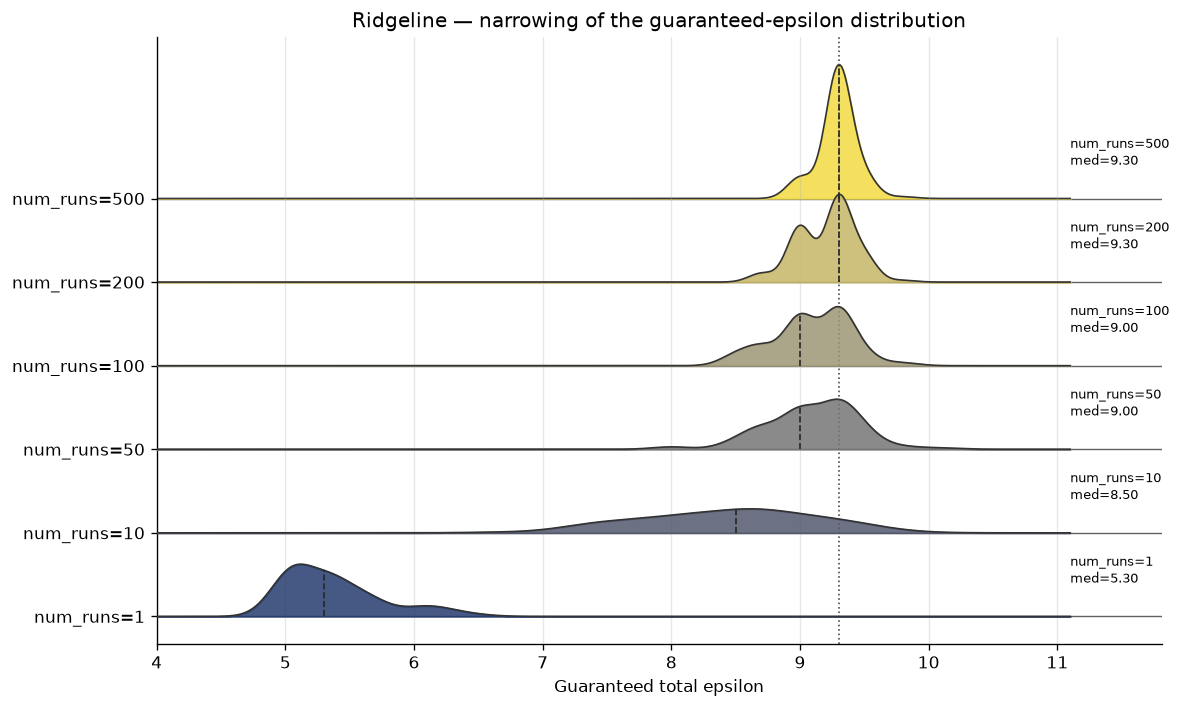

In [72]:
res, summary = run_num_runs_sweep(
    true_mean=TRUE_MEAN, delta=1794, eps=0.1, threshold=0.05, streak_required=3,
    n_list=(1, 10, 50, 100, 200, 500), reps=100,
    success_rate_threshold=0.95, initial_eps_total=5.0, step=1.03, maxq=200)
print(summary)
fig, ax = plot_ridgeline(res)

num_runs가 작을수록 출력 예산의 분산이 커질 뿐 아니라, 라운드마다 재평가되는 탐색 구조로 인해 우연한 조기 통과가 누적되어 예산이 과소 추정되었다(num_runs=1: 중앙값 5.30, num_runs≥200: 9.30). 특히 num_runs < 1/(1−τ)이면 허용 실패 횟수가 0이 되어 τ의 의미가 유지되지 않는다.

num_runs=  50:    3.8s, NaN=0
num_runs= 100:    6.6s, NaN=0
num_runs= 200:   10.6s, NaN=0
num_runs= 300:   16.1s, NaN=0
num_runs= 500:   26.3s, NaN=0
          n_valid  median    mean       std  q05  q95  n_nan
num_runs                                                    
50            500     9.0  9.0358  0.375580  8.5  9.5      0
100           500     9.0  9.0982  0.293375  8.5  9.5      0
200           500     9.3  9.1956  0.225926  8.7  9.5      0
300           500     9.3  9.2444  0.180037  9.0  9.5      0
500           500     9.3  9.2726  0.154522  9.0  9.5      0


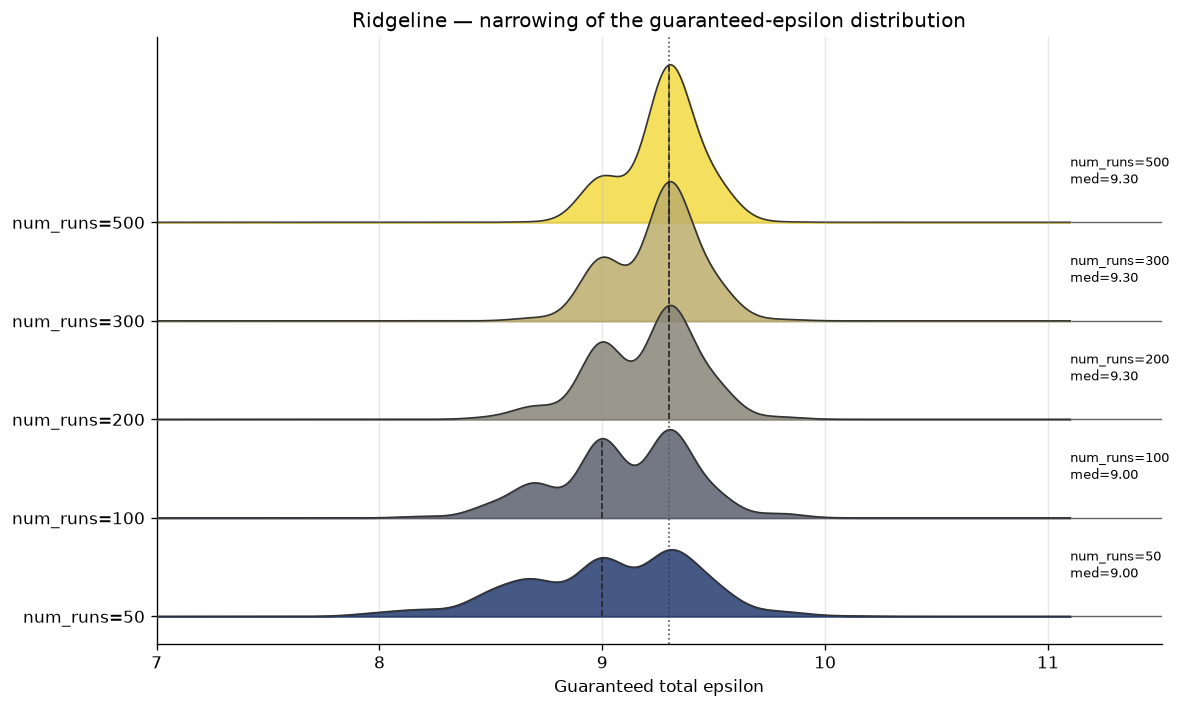

In [74]:
res, summary = run_num_runs_sweep(
    true_mean=TRUE_MEAN, delta=1794, eps=0.1, threshold=0.05, streak_required=3,
    n_list=(50, 100, 200, 300, 500), reps=500,
    success_rate_threshold=0.95, initial_eps_total=5.0, step=1.03, maxq=200)
print(summary)
fig, ax = plot_ridgeline(res)